# Detección binaria de DoS en MQTT — MQTT_UAD

Este notebook entrena **tres modelos binarios de DoS para MQTT sin cifrar**:
XGBoost, LSTM Autoencoder e híbrido LSTM + XGBoost, todos con etiqueta
`normal` o `ataque`, donde `ataque` significa exclusivamente DoS. Cada modelo tiene reporte, confusion matrix, accuracy,
balanced accuracy, macro-F1 y ROC-AUC.
Sus hiperparámetros se optimizan con estudios Optuna independientes y
3-fold grouped cross-validation interna; test queda reservado para la
evaluación final.

Se usa `DoS.csv` completo y **solo el tráfico normal** de `MitM.csv` e
`Intrusion.csv`: sus frames MitM/Intrusion se descartan, no se reetiquetan.
Ningún ataque distinto de DoS entra al entrenamiento, la validación ni la exportación. Se conservan las rutas de entrada y salida.
Las features combinan red/transporte y campos MQTT numéricos, entropía de payload
y estructura de topic. IP, client_id, credenciales, puertos efímeros y tiempos
absolutos/relativos de captura solo sirven de contexto o se excluyen.

La captura admite todas las tramas. El agente clasifica frames IPv4/TCP con
endpoints completos; el notebook aplica esa misma selección. Los CSV no tienen
tcp.stream: se aproximan sesiones mediante endpoints y CONNECT.
Las particiones separan conexiones completas y sus dos direcciones; las
ventanas no cruzan archivos, conexiones, direcciones ni particiones.
No es una prueba de generalización a capturas independientes ni a MQTTS.

In [1]:
import os
import json
import math
import zipfile
from collections import Counter

import numpy as np
import pandas as pd
import joblib
#import optuna
#import torch
#import torch.nn as nn
#from torch.utils.data import DataLoader, TensorDataset
#from xgboost import XGBClassifier-

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             balanced_accuracy_score, f1_score, roc_auc_score)
try:
    import matplotlib.pyplot as plt
    import seaborn as sns
except ImportError:
    plt = sns = None  # Los reportes numéricos siguen funcionando sin librerías de plots.

SEED = 42
SEQ_LEN = 10
N_SPLITS = 5
INNER_SPLITS = 3
NAN_FILL = -1.0
OPTUNA_TRIALS_XGB = 30
OPTUNA_TRIALS_LSTM = 15
OPTUNA_TRIALS_HYBRID = 30
#optuna.logging.set_verbosity(optuna.logging.WARNING)
#np.random.seed(SEED)
#torch.manual_seed(SEED)
#if torch.cuda.is_available():
#    torch.cuda.manual_seed_all(SEED)
#DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#XGB_DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
#print(f'Torch: {DEVICE}; XGBoost: {XGB_DEVICE}')


## 1. Load and select captured frames

`load_and_merge` reads the CSV, validates the fields needed for this pipeline,
normalizes each frame's `type` label, and keeps IPv4/TCP frames with complete
endpoints. It then builds `_connection` and `_direction` for later grouping.
This step reports how many frames are selected; it does not decide which
optional columns to drop based on missingness.


`NORMAL_ONLY` lists captures that contribute only their `normal` frames (MitM
and Intrusion); their attack frames are discarded before validation. The three
captures come from different dates and share no frames, and `_connection`
includes the capture name, so sessions never span files.

In [2]:
from pathlib import Path
import sys

MODEL_CODE_DIR = Path.cwd() / 'ML_Model'
if MODEL_CODE_DIR.is_dir():
    sys.path.insert(0, str(MODEL_CODE_DIR))

from data_preprocessing.load_data import TARGET_COL, load_and_merge

FILES = {
    'DoS': '/home/alejandropenagos/Escritorio/Alejandro/BigData/Proyecto/dataset/DoS.csv',
    'MitM': '/home/alejandropenagos/Escritorio/Alejandro/BigData/Proyecto/dataset/MitM.csv',
    'Intrusion': '/home/alejandropenagos/Escritorio/Alejandro/BigData/Proyecto/dataset/Intrusion.csv',
}

# MitM e Intrusion solo aportan tráfico normal: el modelo sigue siendo DoS vs normal.
NORMAL_ONLY = ['MitM', 'Intrusion']
df_raw = load_and_merge(FILES, normal_only=NORMAL_ONLY)
# Copia sin filtrar: la sección 2 la analiza y 2.7 crea el df_raw filtrado.
df_captured = df_raw
print(f'Selected IPv4/TCP dataset: {df_raw.shape}')
print(df_raw[TARGET_COL].value_counts())
print(pd.crosstab(df_raw['_capture'], df_raw[TARGET_COL], margins=True))

DoS: all frames: {'normal': 49111, 'DoS': 45514}
DoS: excluded due to invalid network context: 6165
DoS: selected IPv4/TCP frames: {'DoS': 45460, 'normal': 43000}
MitM: kept labels ['normal']; discarded {'mitm': 3855}
MitM: all frames: {'normal': 106813}
MitM: excluded due to invalid network context: 7679
MitM: selected IPv4/TCP frames: {'normal': 99134}
Intrusion: kept labels ['normal']; discarded {'intrusion': 1898}
Intrusion: all frames: {'normal': 78995}
Intrusion: excluded due to invalid network context: 9132
Intrusion: selected IPv4/TCP frames: {'normal': 69863}
Selected IPv4/TCP dataset: (257457, 72)
type
normal    211997
DoS        45460
Name: count, dtype: int64
type         DoS  normal     All
_capture                        
DoS        45460   43000   88460
Intrusion      0   69863   69863
MitM           0   99134   99134
All        45460  211997  257457


## 2. EDA y política de descarte de columnas (objetivo: detectar solo DoS)

El modelo distingue únicamente **DoS vs normal**, así que cada columna se juzga
solo frente a ese objetivo. Ninguna se descarta por su % de nulos: para cada una
se registra **semántica, motivo y acción**, y la evidencia sale de las tablas y
gráficas de esta sección.

Las mediciones están en `data_preprocessing/eda.py` (no deciden nada) y las
decisiones en `data_preprocessing/column_policy.py` (`SEMANTICS` y
`build_column_policy`).

### Motivos

| motivo | qué significa | acción |
|---|---|---|
| `EMPTY` | 100% nula | DROP |
| `CONSTANT` | un solo valor observado | DROP |
| `DUPLICATE` | idéntica a otra columna en el 100% de filas | DROP; se indica cuál se conserva |
| `REDUNDANT` | se deriva sin pérdida de otra (verificado bit a bit) | DROP; se indica de cuál |
| `LEAKAGE` | identifica host, puerto efímero o momento de captura, no el comportamiento | DROP del valor crudo (DERIVE si se extrae una bandera) |
| `STRUCTURAL_NULL` | solo existe en cierto tipo de paquete | según la regla de abajo |
| `RAW_TEXT` | texto de aplicación (`mqtt.msg`, `mqtt.topic`) | DERIVE: longitud, entropía, nº de niveles |
| `BEHAVIOR` | siempre presente y describe el tráfico | KEEP |

`BEHAVIOR` es el motivo de las columnas que se conservan sin transformar
(`frame.len`, `frame.time_delta`), para que la tabla no tenga celdas vacías.

### Regla para `STRUCTURAL_NULL`

1. **Alineación**: los no nulos deben coincidir con un tipo de paquete concreto
   (índice de Jaccard ≥ 0.95 entre "tiene valor" y "es de ese tipo"). Si no
   coinciden, la columna mezcla significados y se hace DROP.
2. **Separación**: se compara la proporción de ese tipo en cada clase. Separa si
   una clase lo tiene al menos 2× más que la otra y hay ≥ 10 frames del tipo.
3. Si **no separa**: DROP con el motivo "no discrimina DoS".
4. Si **separa**: la columna cruda no se usa; se deriva un conteo o tasa del tipo
   por ventana o por `_connection` (p. ej. nº de CONNECT por ventana).
5. **Nunca** se imputa con 0 ni con la media: el nulo significa "no aplica".
   Las columnas MQTT que sí entran al modelo usan el centinela `-1`, fuera de su
   dominio (≥ 0).

Orden de evaluación por columna: `EMPTY` → motivos semánticos (`LEAKAGE`,
`RAW_TEXT`, `KEEP` declarados) → `REDUNDANT` verificado → `CONSTANT` →
`DUPLICATE` → `STRUCTURAL_NULL`. Una columna sin semántica escrita hace fallar
la política.

In [3]:
# Re-ejecutar en el mismo kernel recarga data_preprocessing y sus subcarpetas.
import sys
from IPython.display import display

for name in [m for m in sys.modules if m.split('.')[0] == 'data_preprocessing']:
    del sys.modules[name]

from data_preprocessing.feature_engineering import (
    RAW_FEATURE_COLUMNS, ENGINEERED_FEATURE_COLUMNS, FEATURE_COLUMNS, entropy,
)
from data_preprocessing import eda
from data_preprocessing import column_policy as policy_module
from data_preprocessing.column_policy import build_column_policy, apply_column_policy

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 100)

### 2.1 Nulos por columna (solo descripción)

Se mide sobre los frames IPv4/TCP seleccionados. El % de nulos describe la
captura, pero **no decide**: una columna 99% nula puede ser la única que existe en
CONNECT. La gráfica coloreada por motivo aparece en 2.6, cuando ya hay política.

In [4]:
missingness = eda.missingness_report(df_captured)
print(f'Frames: {len(df_captured):,}; columnas capturadas: {len(missingness)}')
print('Columnas 100% nulas:', int(missingness['non_null_count'].eq(0).sum()))
print('Columnas parcialmente nulas:',
      int(missingness['non_null_count'].between(1, len(df_captured) - 1).sum()))
print('Columnas siempre presentes:', int(missingness['missing_count'].eq(0).sum()))
display(missingness)

Frames: 257,457; columnas capturadas: 66
Columnas 100% nulas: 19
Columnas parcialmente nulas: 30
Columnas siempre presentes: 17


,column,non_null_count,n_unique,missing_count,missing_pct
0,frame.coloring_rule.name,0,0,257457,100.00
1,frame.coloring_rule.string,0,0,257457,100.00
2,frame.comment,0,0,257457,100.00
3,frame.comment.expert,0,0,257457,100.00
4,frame.file_off,0,0,257457,100.00
5,frame.incomplete,0,0,257457,100.00
6,frame.interface_id,0,0,257457,100.00
7,frame.interface_name,0,0,257457,100.00
8,frame.link_nr,0,0,257457,100.00
9,frame.md5_hash,0,0,257457,100.00


### 2.2 Tipos de paquete MQTT por clase

El tipo se decodifica de los bits 7-4 de `mqtt.hdrflags`; `NO_MQTT` son frames
TCP sin capa MQTT (handshakes, ACK, otros servicios). Este reparto es la base de
la regla `STRUCTURAL_NULL`: una columna que solo existe en CONNECT solo puede
aportar lo que aporte la presencia de CONNECT. El eje es logarítmico porque hay
tipos con menos del 0.01% de frames.

type,DoS,normal,pct_DoS,pct_normal
packet_type,,,,
PUBLISH,37626,3933,82.767,1.855
NO_MQTT,6416,203972,14.114,96.215
CONNACK,361,108,0.794,0.051
PUBREL,339,0,0.746,0.000
CONNECT,313,153,0.689,0.072
DISCONNECT,175,1,0.385,0.000
PUBACK,162,0,0.356,0.000
PUBCOMP,35,0,0.077,0.000
RESERVED_0,22,0,0.048,0.000


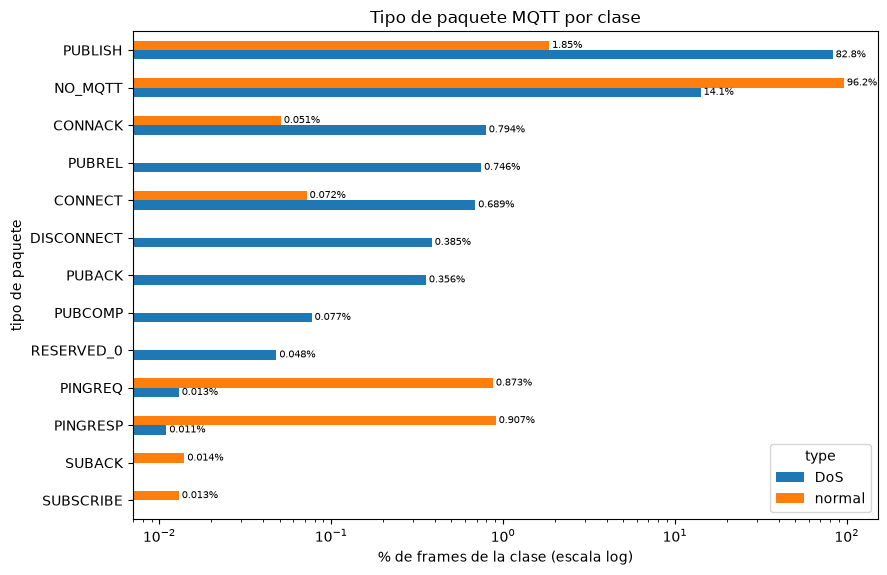

In [5]:
packet_table = eda.packet_type_by_class(df_captured)
display(packet_table)
eda.plot_packet_type_by_class(packet_table)

### 2.3 Rol del puerto MQTT por clase

`tcp.srcport`/`tcp.dstport` son `LEAKAGE` como valor crudo (puertos efímeros) y
solo se usan para derivar `fe_is_standard_mqtt_port` y `fe_is_broker_to_client`.
Esta tabla muestra cuánto separan esas banderas por sí solas.

**Hallazgo**: casi todo el tráfico `normal` de esta captura no usa el puerto
MQTT, mientras que casi todo el DoS va hacia el broker. Las banderas de puerto y
la presencia de MQTT son, en este dataset, casi un proxy de la etiqueta: el
modelo puede aprender "es MQTT" en lugar de "es DoS". Se tiene en cuenta al
interpretar las métricas; el análisis de distribuciones lo retoma.

type,DoS,normal,pct_DoS,pct_normal
port_role,,,,
broker -> cliente,4563,7023,10.04,3.31
cliente -> broker,40767,9301,89.68,4.39
sin puerto MQTT,130,195673,0.29,92.30


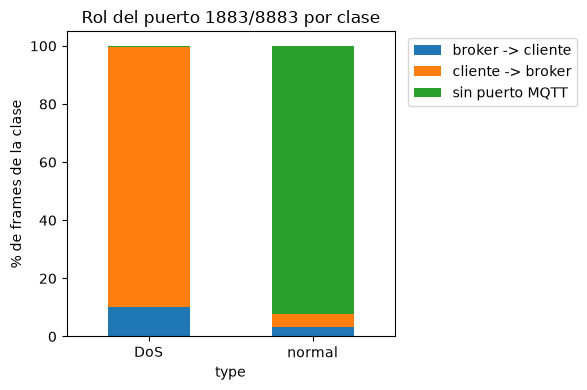

In [6]:
port_table = eda.port_role_by_class(df_captured)
display(port_table)
eda.plot_port_role_by_class(port_table)

#### 2.3.1 ¿MQTT = DoS? Verificación del proxy

La tabla anterior responde "dentro de cada clase, qué rol tiene el frame". Aquí
se invierte: **dentro de cada grupo de frames, qué % es DoS**. Los grupos
combinan el rol del puerto 1883/8883 con la presencia de capa MQTT
(`mqtt.hdrflags` no nulo).

Después se evalúan reglas triviales que no aprenden nada: "si usa el puerto MQTT
⇒ DoS" y "si tiene capa MQTT ⇒ DoS". Si una regla así ya consigue un macro-F1
alto, las métricas de los modelos deben compararse contra ella. Un modelo que no
la supere solo está aprendiendo "es MQTT".

In [7]:
from sklearn.metrics import precision_score, recall_score

attack_name = 'DoS'
src_mqtt = pd.to_numeric(df_captured['tcp.srcport'], errors='coerce').isin([1883, 8883])
dst_mqtt = pd.to_numeric(df_captured['tcp.dstport'], errors='coerce').isin([1883, 8883])
uses_mqtt_port = src_mqtt | dst_mqtt
has_mqtt_layer = df_captured['mqtt.hdrflags'].notna()
is_attack = df_captured[TARGET_COL].eq(attack_name)

port_role = pd.Series(
    np.select([dst_mqtt, src_mqtt], ['cliente -> broker', 'broker -> cliente'], 'sin puerto MQTT'),
    index=df_captured.index)
mqtt_layer = has_mqtt_layer.map({True: 'con capa MQTT', False: 'sin capa MQTT'})

# 1) Composición de clase dentro de cada grupo (% por fila: P(clase | grupo)).
group_counts = pd.crosstab([port_role.rename('rol del puerto'), mqtt_layer.rename('capa')],
                           df_captured[TARGET_COL])
proxy_table = (100 * group_counts.div(group_counts.sum(axis=1), axis=0)).round(2) \
    .add_prefix('% ')
proxy_table.insert(0, 'frames', group_counts.sum(axis=1))
proxy_table.insert(1, '% del total', (100 * proxy_table['frames'] / len(df_captured)).round(2))
display(proxy_table)

# 2) Reglas triviales: predecir DoS solo por la presencia de MQTT.
rules = {
    'puerto MQTT => DoS': uses_mqtt_port,
    'cliente -> broker => DoS': dst_mqtt,
    'capa MQTT => DoS': has_mqtt_layer,
    'puerto MQTT y capa MQTT => DoS': uses_mqtt_port & has_mqtt_layer,
}
baseline = pd.DataFrame([{
    'regla': name,
    'accuracy': accuracy_score(is_attack, predicted),
    'balanced_accuracy': balanced_accuracy_score(is_attack, predicted),
    'precision_DoS': precision_score(is_attack, predicted, zero_division=0),
    'recall_DoS': recall_score(is_attack, predicted, zero_division=0),
    'macro_f1': f1_score(is_attack, predicted, average='macro', zero_division=0),
} for name, predicted in rules.items()]).set_index('regla').round(4)
display(baseline)

if plt is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [3, 2]})
    shares = proxy_table[[f'% {label}' for label in group_counts.columns]]
    shares.index = [f'{role} | {layer} (n={n:,})'
                    for (role, layer), n in zip(shares.index, proxy_table['frames'])]
    shares.iloc[::-1].plot.barh(stacked=True, ax=axes[0], color=['#c0392b', '#4e79a7'])
    axes[0].axvline(100 * is_attack.mean(), color='black', ls='--', lw=1,
                    label=f'% DoS global ({100 * is_attack.mean():.1f}%)')
    axes[0].set(xlabel='% de frames del grupo', xlim=(0, 100),
                title='Composición de clase dentro de cada grupo')
    axes[0].legend(loc='lower right', fontsize=8)
    baseline[['balanced_accuracy', 'macro_f1']].plot.barh(ax=axes[1])
    axes[1].set(xlim=(0, 1), xlabel='métrica', title='Reglas triviales (sin modelo)')
    axes[1].invert_yaxis()
    axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)
    fig.tight_layout()
    plt.show()

type                             frames  % del total  % DoS  % normal
rol del puerto    capa                                               
broker -> cliente con capa MQTT    2707         1.05  11.64     88.36
                  sin capa MQTT    8879         3.45  47.84     52.16
cliente -> broker con capa MQTT   44362        17.23  87.30     12.70
                  sin capa MQTT    5706         2.22  35.72     64.28
sin puerto MQTT   sin capa MQTT  195803        76.05   0.07     99.93

,accuracy,balanced_accuracy,precision_DoS,recall_DoS,macro_f1
regla,,,,,
puerto MQTT => DoS,0.9361,0.9601,0.7352,0.9971,0.9030
cliente -> broker => DoS,0.9456,0.9264,0.8142,0.8968,0.9101
capa MQTT => DoS,0.9439,0.9105,0.8295,0.8589,0.9049
puerto MQTT y capa MQTT => DoS,0.9439,0.9105,0.8295,0.8589,0.9049


#### 2.3.2 ¿Cambia la distribución al añadir el normal de MitM e Intrusion?

Se compara el tráfico normal de cada captura de origen y luego la misma regla
trivial de 2.3.1 ("puerto MQTT ⇒ DoS") con solo `DoS.csv` y con la mezcla. Si
el normal añadido usa más MQTT, la regla pierde precisión y el proxy
"MQTT = DoS" se debilita. Si no cambia, el normal extra no corrige el sesgo.

In [8]:
from sklearn.metrics import precision_score, recall_score

ports = df_captured[['tcp.srcport', 'tcp.dstport']].apply(pd.to_numeric, errors='coerce')
uses_mqtt_port = ports.isin([1883, 8883]).any(axis=1)
has_mqtt_layer = df_captured['mqtt.hdrflags'].notna()
frame_types = eda.packet_types(df_captured)
is_normal = df_captured[TARGET_COL].eq('normal')
capture = df_captured['_capture']

# 1) Perfil del tráfico normal por captura de origen.
normal_profile = pd.DataFrame({
    'frames normales': is_normal.groupby(capture).sum(),
    'conexiones normales': df_captured[is_normal].groupby('_capture')['_connection'].nunique(),
    '% puerto MQTT': 100 * uses_mqtt_port[is_normal].groupby(capture[is_normal]).mean(),
    '% capa MQTT': 100 * has_mqtt_layer[is_normal].groupby(capture[is_normal]).mean(),
    '% PUBLISH': 100 * frame_types[is_normal].eq('PUBLISH').groupby(capture[is_normal]).mean(),
    'frame.len mediana': pd.to_numeric(df_captured.loc[is_normal, 'frame.len'])
        .groupby(capture[is_normal]).median(),
}).round(2)
display(normal_profile)

# 2) Tipos de paquete del normal por captura (% dentro de cada captura).
normal_types = (100 * pd.crosstab(frame_types[is_normal], capture[is_normal],
                                  normalize='columns')).round(3)
display(normal_types.sort_values(normal_types.columns[0], ascending=False))

# 3) Regla trivial "puerto MQTT => DoS": solo DoS.csv vs mezcla completa.
scopes = {'solo DoS.csv': capture.eq('DoS'), 'DoS.csv + normal MitM/Intrusion': capture.notna()}
rule_rows = []
for scope_name, mask in scopes.items():
    actual, predicted = ~is_normal[mask], uses_mqtt_port[mask]
    rule_rows.append({
        'datos': scope_name, 'frames': int(mask.sum()),
        '% DoS': round(100 * actual.mean(), 2),
        'balanced_accuracy': balanced_accuracy_score(actual, predicted),
        'precision_DoS': precision_score(actual, predicted, zero_division=0),
        'recall_DoS': recall_score(actual, predicted, zero_division=0),
        'macro_f1': f1_score(actual, predicted, average='macro', zero_division=0),
    })
rule_comparison = pd.DataFrame(rule_rows).set_index('datos').round(4)
display(rule_comparison)

if plt is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    normal_profile[['% puerto MQTT', '% capa MQTT', '% PUBLISH']].plot.bar(ax=axes[0], rot=0)
    axes[0].set(ylabel='% de frames normales', xlabel='captura de origen',
                title='Tráfico normal por captura')
    for container in axes[0].containers:
        axes[0].bar_label(container, fmt='%.1f', fontsize=7)
    rule_comparison[['balanced_accuracy', 'precision_DoS', 'macro_f1']].T.plot.bar(
        ax=axes[1], rot=0)
    axes[1].set(ylim=(0, 1.05), title='Regla "puerto MQTT => DoS"')
    axes[1].legend(fontsize=8, loc='lower left')
    fig.tight_layout()
    plt.show()

,frames normales,conexiones normales,% puerto MQTT,% capa MQTT,% PUBLISH,frame.len mediana
_capture,,,,,,
DoS,43000,697,2.25,1.14,0.55,612.0
Intrusion,69863,2067,11.02,5.67,2.44,74.0
MitM,99134,864,7.72,3.60,2.01,353.0


_capture,DoS,Intrusion,MitM
packet_type,,,
NO_MQTT,98.858,94.329,96.397
PUBLISH,0.551,2.445,2.005
PINGRESP,0.256,1.439,0.814
PINGREQ,0.253,1.397,0.773
CONNACK,0.040,0.120,0.007
CONNECT,0.023,0.199,0.004
SUBACK,0.009,0.036,0.000
SUBSCRIBE,0.009,0.034,0.000
DISCONNECT,0.000,0.001,0.000


,frames,% DoS,balanced_accuracy,precision_DoS,recall_DoS,macro_f1
datos,,,,,,
solo DoS.csv,88460,51.39,0.9873,0.9791,0.9971,0.9876
DoS.csv + normal MitM/Intrusion,257457,17.66,0.9601,0.7352,0.9971,0.9030


#### 2.3.3 ¿El tráfico normal de DoS, MitM e Intrusion es el mismo?

Si las tres capturas tienen el mismo tipo de tráfico normal, mezclarlas solo
añade volumen. Si son distintas, el modelo puede aprender "de qué captura viene"
en lugar de "es DoS". La evaluación tiene cuatro partes, todas solo con frames normales:

1. **Numéricas**: mediana/IQR y estadístico KS `D` por pares. Con cientos de
   miles de frames cualquier p-valor es ~0, así que se usa `D` como tamaño de
   efecto: < 0.1 pequeño, 0.1–0.3 moderado, > 0.3 grande. `frame.time_delta` se
   mide entre frames consecutivos de toda la captura, así que también refleja
   cuánto tráfico total había ese día.
2. **Categóricas**: tipo de paquete y rol del puerto, con distancia de
   Jensen-Shannon por pares (0 = idénticas, 1 = disjuntas).
3. **Hosts**: solapamiento (Jaccard) de las IP vistas en cada captura.
4. **Clasificador de origen**: un modelo intenta adivinar la captura de cada
   frame normal con 5-fold agrupado por conexión. El azar es 1/3 de balanced
   accuracy. Cuanto más se acerque a 1, más distintas son las capturas.

In [9]:
from itertools import combinations
from scipy.spatial.distance import jensenshannon
from scipy.stats import ks_2samp
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict

normal_frames = df_captured[df_captured[TARGET_COL].eq('normal')]
sources = sorted(normal_frames['_capture'].unique())
source = normal_frames['_capture']
pairs = list(combinations(sources, 2))

numeric = pd.DataFrame({
    column: pd.to_numeric(normal_frames[column], errors='coerce')
    for column in ['frame.len', 'frame.time_delta', 'mqtt.len', 'mqtt.topic_len']
})

# 1) Numéricas: resumen por captura (solo valores observados) y KS D por pares.
summary = numeric.groupby(source).agg(['median', lambda s: s.quantile(.75) - s.quantile(.25)])
summary.columns = [f'{col} {"mediana" if stat == "median" else "IQR"}'
                   for col, stat in summary.columns]
summary['% con capa MQTT'] = 100 * numeric['mqtt.len'].notna().groupby(source).mean()
display(summary.round(5))

ks_table = pd.DataFrame({
    f'{a} vs {b}': {column: ks_2samp(numeric.loc[source.eq(a), column].dropna(),
                                     numeric.loc[source.eq(b), column].dropna()).statistic
                    for column in numeric}
    for a, b in pairs
}).round(3)
print('KS D por pares (tamaño de efecto: <0.1 pequeño, 0.1-0.3 moderado, >0.3 grande)')
display(ks_table)

# 2) Categóricas: distancia de Jensen-Shannon por pares.
ports = normal_frames[['tcp.srcport', 'tcp.dstport']].apply(pd.to_numeric, errors='coerce')
# Puerto de servicio = el menor del par si es conocido (<1024) o MQTT; si no, efímero/otro.
low_port = ports.min(axis=1)
service_port = low_port.astype(int).astype(str).where(
    (low_port < 1024) | low_port.isin([1883, 8883]), 'efímero/otro').rename('puerto')
categorical = {
    'tipo de paquete': eda.packet_types(normal_frames),
    'rol del puerto': pd.Series(np.select(
        [ports['tcp.dstport'].isin([1883, 8883]), ports['tcp.srcport'].isin([1883, 8883])],
        ['cliente -> broker', 'broker -> cliente'], 'sin puerto MQTT'), index=normal_frames.index),
    'puerto de servicio': service_port,
}
js_rows = {}
for name, values in categorical.items():
    dist = pd.crosstab(values, source, normalize='columns')
    js_rows[name] = {f'{a} vs {b}': jensenshannon(dist[a], dist[b], base=2) for a, b in pairs}
print('Distancia de Jensen-Shannon por pares (0 = idénticas, 1 = disjuntas)')
display(pd.DataFrame(js_rows).T.round(3))
service = pd.crosstab(categorical['puerto de servicio'], source, normalize='columns') * 100
print('Top puertos de servicio (% de frames normales de cada captura)')
display(service.loc[service.max(axis=1).sort_values(ascending=False).index[:8]].round(2))

# 3) Hosts: ¿son los mismos dispositivos?
hosts = {name: set(normal_frames.loc[source.eq(name), 'ip.src'])
              | set(normal_frames.loc[source.eq(name), 'ip.dst']) for name in sources}
host_table = pd.DataFrame([{
    'par': f'{a} vs {b}', 'IPs en A': len(hosts[a]), 'IPs en B': len(hosts[b]),
    'IPs compartidas': len(hosts[a] & hosts[b]),
    'Jaccard': round(len(hosts[a] & hosts[b]) / len(hosts[a] | hosts[b]), 3),
} for a, b in pairs]).set_index('par')
display(host_table)

# 4) Clasificador de origen sobre features de comportamiento (sin IP ni puertos crudos).
origin_X = numeric.fillna(-1).assign(
    hdrflags=eda.parse_hdrflags(normal_frames['mqtt.hdrflags']).fillna(-1),
    to_broker=ports['tcp.dstport'].isin([1883, 8883]).astype(int),
    from_broker=ports['tcp.srcport'].isin([1883, 8883]).astype(int),
)
origin_y = source.to_numpy()
origin_groups = pd.factorize(normal_frames['_connection'].map(str))[0]
origin_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
origin_pred = cross_val_predict(
    HistGradientBoostingClassifier(max_iter=200, random_state=SEED, class_weight='balanced'),
    origin_X, origin_y, groups=origin_groups, cv=origin_cv)
origin_bacc = balanced_accuracy_score(origin_y, origin_pred)
print(f'Clasificador de origen: balanced accuracy = {origin_bacc:.3f} (azar = {1 / len(sources):.3f})')
origin_cm = pd.DataFrame(confusion_matrix(origin_y, origin_pred, labels=sources, normalize='true'),
                         index=[f'real {s}' for s in sources],
                         columns=[f'pred {s}' for s in sources]).round(3)
display(origin_cm)

if plt is not None:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for name in sources:
        for ax, column, transform in [(axes[0], 'frame.len', np.asarray),
                                      (axes[1], 'frame.time_delta', lambda v: np.log10(v + 1e-6))]:
            values = np.sort(transform(numeric.loc[source.eq(name), column].dropna().to_numpy()))
            ax.plot(values, np.arange(1, len(values) + 1) / len(values), label=name)
    axes[0].set(xlabel='frame.len (bytes)', ylabel='proporción acumulada', title='ECDF frame.len (normal)')
    axes[1].set(xlabel='log10(frame.time_delta + 1e-6)', title='ECDF frame.time_delta (normal)')
    for ax in axes[:2]:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    image = axes[2].imshow(origin_cm.to_numpy(), cmap='Blues', vmin=0, vmax=1)
    axes[2].set_xticks(range(len(sources)), sources)
    axes[2].set_yticks(range(len(sources)), sources)
    for (i, j), value in np.ndenumerate(origin_cm.to_numpy()):
        axes[2].text(j, i, f'{value:.2f}', ha='center', va='center',
                     color='white' if value > 0.6 else 'black')
    axes[2].set(xlabel='captura predicha', ylabel='captura real',
                title=f'Clasificador de origen (bacc={origin_bacc:.2f}, azar=0.33)')
    fig.colorbar(image, ax=axes[2])
    fig.tight_layout()
    plt.show()

,frame.len mediana,frame.len IQR,frame.time_delta mediana,frame.time_delta IQR,mqtt.len mediana,mqtt.len IQR,mqtt.topic_len mediana,mqtt.topic_len IQR,% con capa MQTT
_capture,,,,,,,,,
DoS,612.0,1448.0,0.00013,0.00096,8.0,14.0,11.0,9.0,1.14186
Intrusion,74.0,954.5,0.00050,0.00423,0.0,25.0,20.0,0.0,5.67110
MitM,353.0,1448.0,0.00013,0.00122,25.0,25.0,20.0,0.0,3.60320


KS D por pares (tamaño de efecto: <0.1 pequeño, 0.1-0.3 moderado, >0.3 grande)


,DoS vs Intrusion,DoS vs MitM,Intrusion vs MitM
frame.len,0.303,0.100,0.288
frame.time_delta,0.181,0.074,0.141
mqtt.len,0.343,0.470,0.128
mqtt.topic_len,0.608,0.639,0.030


Distancia de Jensen-Shannon por pares (0 = idénticas, 1 = disjuntas)


,DoS vs Intrusion,DoS vs MitM,Intrusion vs MitM
tipo de paquete,0.111,0.075,0.057
rol del puerto,0.156,0.110,0.049
puerto de servicio,0.348,0.352,0.059


Top puertos de servicio (% de frames normales de cada captura)


_capture,DoS,Intrusion,MitM
puerto,,,
443,52.63,72.77,78.08
80,30.02,3.60,3.04
efímero/otro,15.07,12.61,11.11
1883,2.25,11.02,7.72
22,0.03,0.00,0.04


,IPs en A,IPs en B,IPs compartidas,Jaccard
par,,,,
DoS vs Intrusion,176,427,63,0.117
DoS vs MitM,176,234,45,0.123
Intrusion vs MitM,427,234,40,0.064


Clasificador de origen: balanced accuracy = 0.485 (azar = 0.333)


,pred DoS,pred Intrusion,pred MitM
real DoS,0.527,0.261,0.212
real Intrusion,0.254,0.639,0.106
real MitM,0.429,0.284,0.287


#### 2.3.4 Concurrencia temporal del normal en `DoS.csv`

Antes de decidir el split hay que saber si el normal de `DoS.csv` existe durante
el ataque o solo antes/después. Se miran dos vistas con `frame.time_epoch`: puntos
por frame y frames por segundo apilados por clase. Se repiten solo con frames del
puerto 1883/8883, que es el alcance del experimento A/B.

La tabla final compara los frames normales antes, durante y después de la ventana
`[primer DoS, último DoS]`, en total y solo MQTT.

**Decisión.** Si ≥ 20 % del normal MQTT de `DoS.csv` cae dentro de la ventana, se
mantiene la división agrupada por conexión. Si no, además se evaluará
*leave-one-capture-out* del normal para separar "reconoce normal" de "reconoce
antes/después del ataque".

In [10]:
dos_capture = df_captured[df_captured['_capture'].eq('DoS')].copy()
dos_time = pd.to_numeric(dos_capture['frame.time_epoch'], errors='coerce')
dos_ports = dos_capture[['tcp.srcport', 'tcp.dstport']].apply(
    pd.to_numeric, errors='coerce')
dos_mqtt_port = dos_ports.isin([1883, 8883]).any(axis=1)
dos_attack = dos_capture[TARGET_COL].eq('DoS')
dos_normal = dos_capture[TARGET_COL].eq('normal')

attack_start = float(dos_time[dos_attack].min())
attack_end = float(dos_time[dos_attack].max())
during = (dos_time >= attack_start) & (dos_time <= attack_end)
before = dos_time < attack_start
after = dos_time > attack_end

rows = []
for name, mask in [('antes', before), ('durante', during), ('después', after)]:
    rows.append({
        'ventana': name,
        'normal_total': int((dos_normal & mask).sum()),
        'normal_mqtt': int((dos_normal & mask & dos_mqtt_port).sum()),
        'DoS_total': int((dos_attack & mask).sum()),
        'DoS_mqtt': int((dos_attack & mask & dos_mqtt_port).sum()),
    })
rows.append({
    'ventana': 'total',
    'normal_total': int(dos_normal.sum()),
    'normal_mqtt': int((dos_normal & dos_mqtt_port).sum()),
    'DoS_total': int(dos_attack.sum()),
    'DoS_mqtt': int((dos_attack & dos_mqtt_port).sum()),
})
temporal_table = pd.DataFrame(rows).set_index('ventana')
display(temporal_table)

normal_mqtt_total = int((dos_normal & dos_mqtt_port).sum())
normal_mqtt_during = int((dos_normal & during & dos_mqtt_port).sum())
NORMAL_CONCURRENT_SHARE = (
    normal_mqtt_during / normal_mqtt_total if normal_mqtt_total else 0.0
)
NEEDS_LOCO = NORMAL_CONCURRENT_SHARE < 0.20
print(f'Ventana DoS: {attack_start:.3f} -> {attack_end:.3f} '
      f'({attack_end - attack_start:.1f} s)')
print(f'Normal MQTT de DoS.csv dentro de la ventana: '
      f'{normal_mqtt_during}/{normal_mqtt_total} = {NORMAL_CONCURRENT_SHARE:.1%}')
print('Split:', 'agrupado por conexión' if not NEEDS_LOCO
      else 'agrupado + leave-one-capture-out del normal')

if plt is not None:
    duration = attack_end - attack_start
    views = [
        (dos_capture, 'todos los frames'),
        (dos_capture[dos_mqtt_port], 'solo puerto 1883/8883'),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex='col')
    for column, (frame, title) in enumerate(views):
        if frame.empty:
            axes[0, column].set_title(f'{title}: sin frames')
            axes[1, column].set_title(f'{title}: sin frames')
            continue
        relative = pd.to_numeric(
            frame['frame.time_epoch'], errors='coerce') - attack_start
        for label, color, offset in [('normal', 'tab:blue', 0.0),
                                     ('DoS', 'tab:red', 1.0)]:
            selected = frame[TARGET_COL].eq(label)
            axes[0, column].scatter(
                relative[selected], np.full(int(selected.sum()), offset),
                s=2, alpha=0.25, color=color, label=label)
        for axis in axes[:, column]:
            axis.axvline(0, color='black', linestyle='--', linewidth=1)
            axis.axvline(duration, color='black', linestyle='--', linewidth=1)
        axes[0, column].set_yticks([0, 1], ['normal', 'DoS'])
        axes[0, column].set_title(f'Puntos por frame ({title})')
        axes[0, column].set_xlabel('segundos desde el primer DoS')
        axes[0, column].legend(markerscale=3, fontsize=8)

        second = np.floor(relative).astype(int)
        lo, hi = int(second.min()), int(second.max())
        counts = pd.crosstab(second, frame[TARGET_COL]).reindex(
            range(lo, hi + 1), fill_value=0)
        for label in ('normal', 'DoS'):
            if label not in counts.columns:
                counts[label] = 0
        axes[1, column].bar(
            counts.index, counts['normal'], width=1.0,
            color='tab:blue', label='normal')
        axes[1, column].bar(
            counts.index, counts['DoS'], bottom=counts['normal'],
            width=1.0, color='tab:red', label='DoS')
        axes[1, column].set_title(f'Frames por segundo ({title})')
        axes[1, column].set_xlabel('segundos desde el primer DoS')
        axes[1, column].set_ylabel('frames/s')
        axes[1, column].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

,normal_total,normal_mqtt,DoS_total,DoS_mqtt
ventana,,,,
antes,12263,198,0,0
durante,23306,568,45460,45330
después,7431,203,0,0
total,43000,969,45460,45330


Ventana DoS: 1522235596.011 -> 1522236159.872 (563.9 s)
Normal MQTT de DoS.csv dentro de la ventana: 568/969 = 58.6%
Split: agrupado por conexión


### 2.4 Duplicadas y redundantes

- **DUPLICATE**: columnas idénticas celda a celda (nulos incluidos). Se conserva
  la que usa el modelo o, si ninguna, la primera.
- **REDUNDANT**: `mqtt.msgtype`, `mqtt.dupflag`, `mqtt.qos` y `mqtt.retain` son
  bits de `mqtt.hdrflags`. Se verifican donde tienen significado: el tipo en todo
  frame MQTT y DUP/QoS/RETAIN solo en PUBLISH (MQTT 3.1.1). Fuera de PUBLISH
  tshark también rellena esos campos aunque los bits no signifiquen eso; esas
  diferencias se cuentan aparte y no invalidan la redundancia.

In [11]:
display(eda.duplicate_columns(df_captured, preferred=policy_module.PREFERRED_COLUMNS))
display(eda.hdrflags_redundancy(df_captured))

,duplicate_of
column,
frame.time_delta_displayed,frame.time_delta
frame.cap_len,frame.len
frame.marked,frame.ignored
mqtt.conflag.qos,mqtt.conflag.passwd
mqtt.conflag.reserved,mqtt.conflag.passwd
mqtt.conflag.retain,mqtt.conflag.passwd
mqtt.conflag.uname,mqtt.conflag.passwd
mqtt.conflag.willflag,mqtt.conflag.passwd


,source,bits,scope,compared_in_scope,mismatches_in_scope,mismatches_out_of_scope,out_of_scope_types,only_in_derived
column,,,,,,,,
mqtt.msgtype,mqtt.hdrflags,7-4,MQTT,47069,0,0,-,0
mqtt.dupflag,mqtt.hdrflags,3-3,PUBLISH,41559,0,230,"PUBREL=86, PUBACK=66, CONNACK=54, RESERVED_0=20, PUBCOMP=4",0
mqtt.qos,mqtt.hdrflags,2-1,PUBLISH,41559,0,442,"PUBREL=294, PUBACK=100, RESERVED_0=20, PUBCOMP=16, CONNACK=12",0
mqtt.retain,mqtt.hdrflags,0-0,PUBLISH,41559,0,289,"PUBREL=162, PUBACK=71, CONNACK=54, RESERVED_0=2",0


### 2.5 `STRUCTURAL_NULL`: alineación y separación

**Paso 1.** El heatmap muestra, para cada columna parcialmente nula, en qué % de
los frames de cada tipo tiene valor. Una columna alineada tiene una sola celda
llena, como las de CONNECT. `mqtt.conack.*` y `mqtt.msgid` aparecen en varios
tipos: no son "campos de CONNACK" en esta captura y se descartan.

**Paso 2.** La tabla y el scatter comparan la proporción de cada tipo en normal y
DoS; la diagonal es "misma proporción". Los puntos rojos separan.

,non_null,best_group,jaccard,precision,coverage,aligned,non_null_by_type
column,,,,,,,
mqtt.sub.qos,28,SUBSCRIBE,1.0000,1.000000,1.000000,True,SUBSCRIBE=28
mqtt.suback.qos,29,SUBACK,1.0000,1.000000,1.000000,True,SUBACK=29
mqtt.clientid,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.clientid_len,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.conflag.cleansess,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.conflag.passwd,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.conflag.qos,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.conflag.reserved,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466
mqtt.conflag.retain,466,CONNECT,1.0000,1.000000,1.000000,True,CONNECT=466


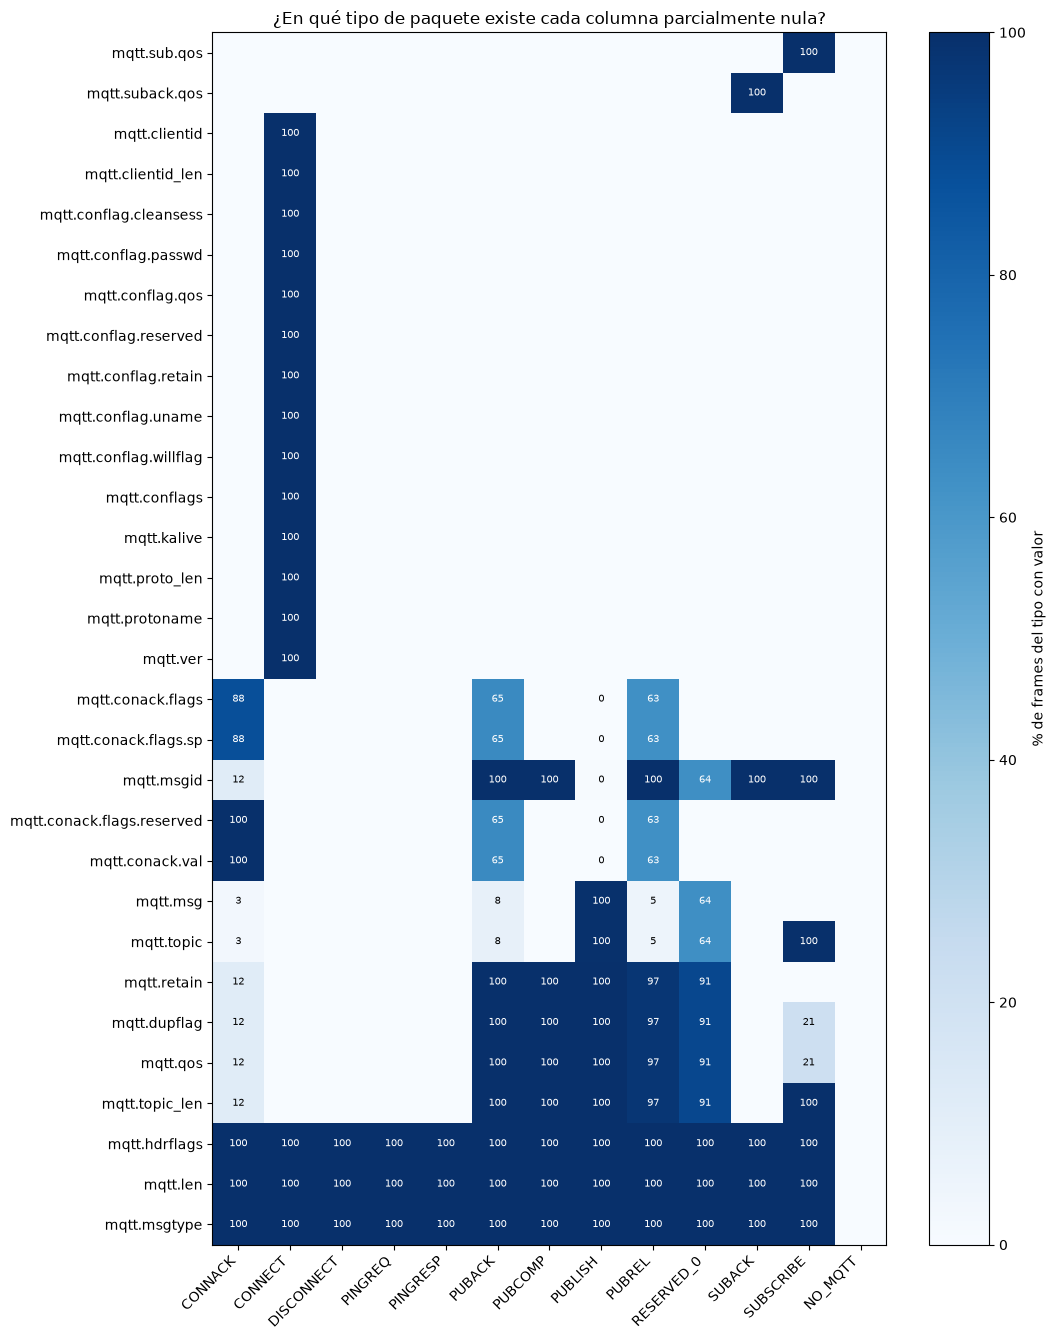

,count_normal,count_attack,pct_normal,pct_attack,ratio,separates
group,,,,,,
SUBSCRIBE,28,0,0.013208,0.000000,inf,True
SUBACK,29,0,0.013679,0.000000,inf,True
PUBCOMP,0,35,0.000000,0.076991,inf,True
PUBACK,0,162,0.000000,0.356357,inf,True
PUBREL,0,339,0.000000,0.745711,inf,True
RESERVED_0,0,22,0.000000,0.048394,inf,True
DISCONNECT,1,175,0.000472,0.384954,816.090519,True
PINGRESP,1922,5,0.906617,0.010999,82.429582,True
PINGREQ,1851,6,0.873126,0.013198,66.153813,True


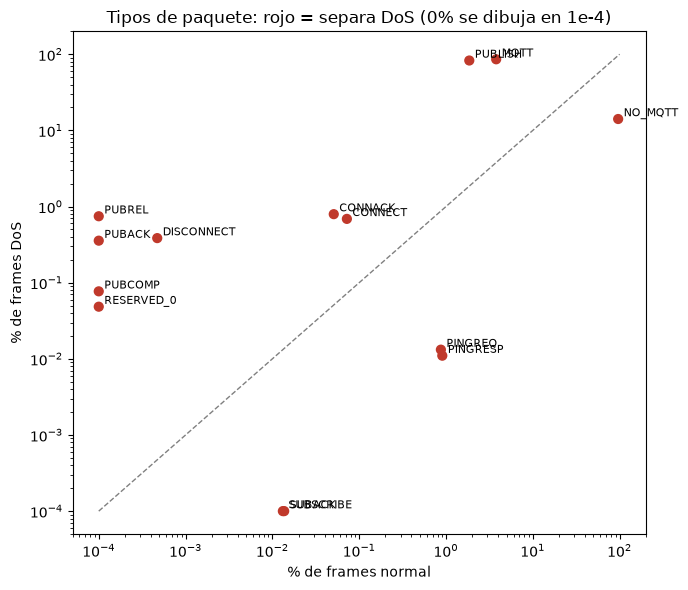

In [12]:
partial_columns = missingness.loc[
    missingness['non_null_count'].between(1, len(df_captured) - 1), 'column'].tolist()
alignment = eda.structural_null_alignment(df_captured, partial_columns)
display(alignment)
eda.plot_structural_presence(df_captured, partial_columns)

separation = eda.packet_type_separation(df_captured)
display(separation)
eda.plot_packet_separation(separation)

CONNECT separa por proporción de frames, así que sus columnas no constantes
(`mqtt.kalive`, `mqtt.clientid_len`, y con el normal de MitM/Intrusion también
`mqtt.ver`, `mqtt.proto_len` y `mqtt.protoname`) se marcan DERIVE: la señal útil
es cuántos CONNECT hay por ventana o por conexión, no el valor crudo. Las gráficas
lo muestran a nivel de conexión y la distribución de valores de esas columnas.

Los valores crudos describen el cliente, no el comportamiento: todo CONNECT DoS
usa MQTT 3.1.1 (`ver=4`, `MQTT`) y el 73% de los CONNECT normales usa MQTT 3.1
(`ver=3`, `MQIsdp`). Usarlos crudos enseñaría al modelo a reconocer la librería
de la herramienta de ataque.

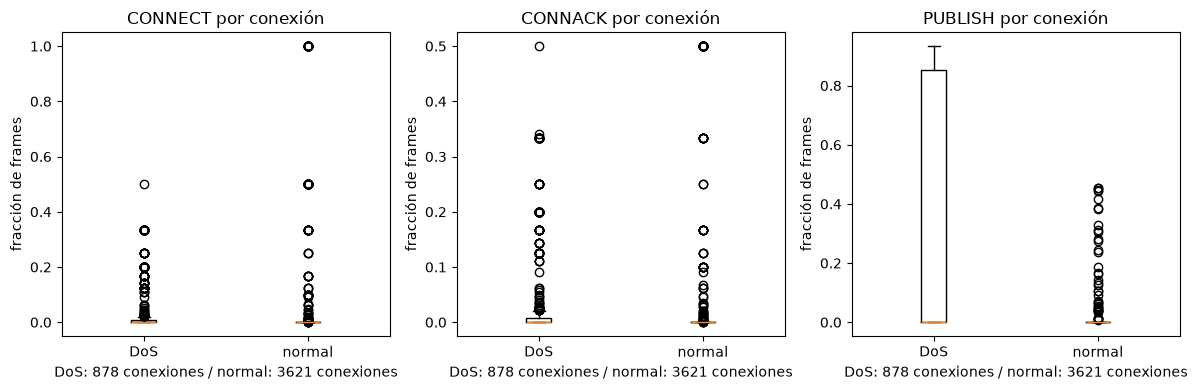

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
DoS,878.0,0.039459,0.090290,0.0,0.0,0.0,0.008132,0.5
normal,3621.0,0.018923,0.114379,0.0,0.0,0.0,0.000000,1.0


type,DoS,normal,pct_DoS,pct_normal
mqtt.kalive,,,,
15.0,5,41,1.6,26.8
60.0,308,112,98.4,73.2


type,DoS,normal,pct_DoS,pct_normal
mqtt.clientid_len,,,,
9.0,0,19,0.00,12.42
11.0,0,29,0.00,18.95
12.0,0,1,0.00,0.65
13.0,1,1,0.32,0.65
14.0,1,11,0.32,7.19
16.0,0,58,0.00,37.91
18.0,2,12,0.64,7.84
23.0,0,6,0.00,3.92
34.0,0,13,0.00,8.50


type,DoS,normal,pct_DoS,pct_normal
mqtt.ver,,,,
3.0,0,112,0.0,73.2
4.0,313,41,100.0,26.8


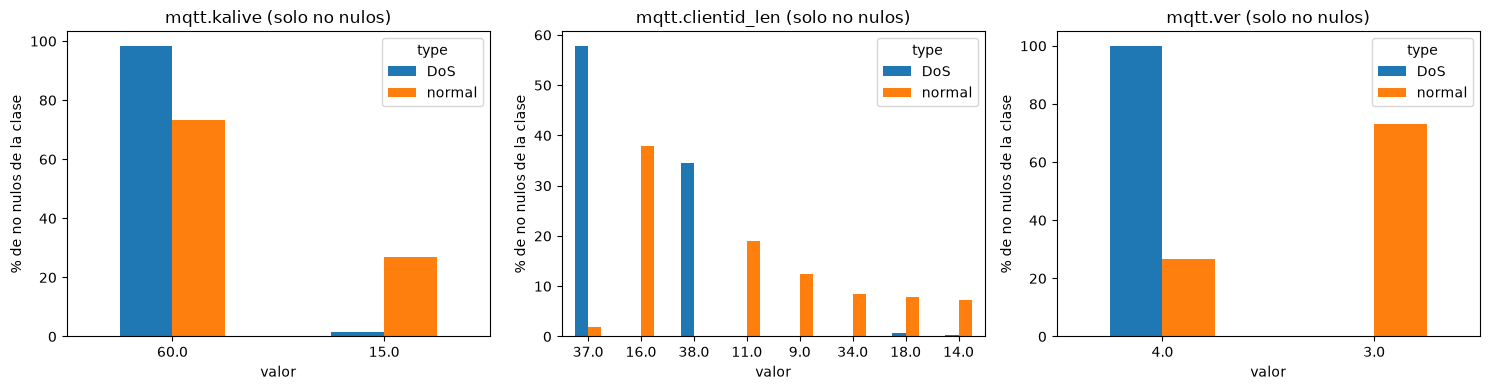

In [13]:
eda.plot_connection_packet_share(df_captured, ['CONNECT', 'CONNACK', 'PUBLISH'])
display(eda.connection_packet_share(df_captured, 'CONNECT')
        .groupby('label')['share'].describe())
for column in ['mqtt.kalive', 'mqtt.clientid_len', 'mqtt.ver']:
    display(eda.values_by_class(df_captured, column))
eda.plot_values_by_class(df_captured, ['mqtt.kalive', 'mqtt.clientid_len', 'mqtt.ver'])

### 2.6 Tabla de política

Una fila por columna capturada, sin celdas vacías. La justificación de las
decisiones dependientes de datos se genera con los números de 2.1–2.5.

Pendiente: los DERIVE de CONNECT (nº de CONNECT por ventana/conexión) aún **no**
están en `FEATURE_COLUMNS`; añadirlos cambia el contrato de features y obliga a
reentrenar y reexportar `modelos_agente/`.

,columna,semántica,motivo,acción,justificación frente a DoS
0,frame.time_delta,segundos desde el frame capturado anterior,BEHAVIOR,KEEP,ritmo entre frames; la inundación DoS lo acorta
1,frame.time_delta_displayed,segundos desde el frame mostrado anterior en tshark,DUPLICATE,DROP,idéntica a frame.time_delta en el 100% de filas; se conserva frame.time_delta
2,frame.time_epoch,instante absoluto de captura (Unix epoch),LEAKAGE,DROP,fecha de captura; solo se usa como contexto para ordenar ventanas
3,frame.time_invalid,marca de timestamp inválido,EMPTY,DROP,sin ningún valor observado
4,frame.time_relative,segundos desde el primer frame de la captura,LEAKAGE,DROP,momento dentro de la captura; separa por cuándo se grabó el ataque
5,ip.src,dirección IP de origen,LEAKAGE,DROP,"identifica al host, no el comportamiento"
6,ip.dst,dirección IP de destino,LEAKAGE,DROP,"identifica al host, no el comportamiento"
7,tcp.srcport,puerto TCP de origen,LEAKAGE,DERIVE,puerto efímero; solo se deriva fe_is_broker_to_client (origen 1883/8883)
8,tcp.dstport,puerto TCP de destino,LEAKAGE,DERIVE,puerto efímero; solo se deriva fe_is_standard_mqtt_port (destino 1883/8883)
9,eth.src,MAC de origen,LEAKAGE,DROP,"identifica la interfaz física, no el comportamiento"


columnas
acción motivo                   
DERIVE LEAKAGE                 2
       RAW_TEXT                2
       STRUCTURAL_NULL         5
DROP   CONSTANT               14
       DUPLICATE               2
       EMPTY                  19
       LEAKAGE                 8
       REDUNDANT               4
       STRUCTURAL_NULL         5
KEEP   BEHAVIOR                2
       STRUCTURAL_NULL         3

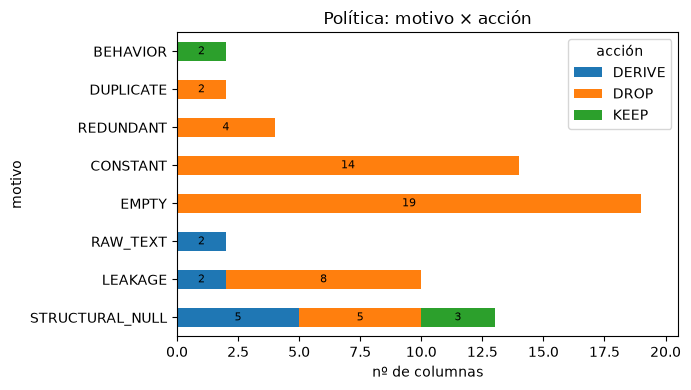

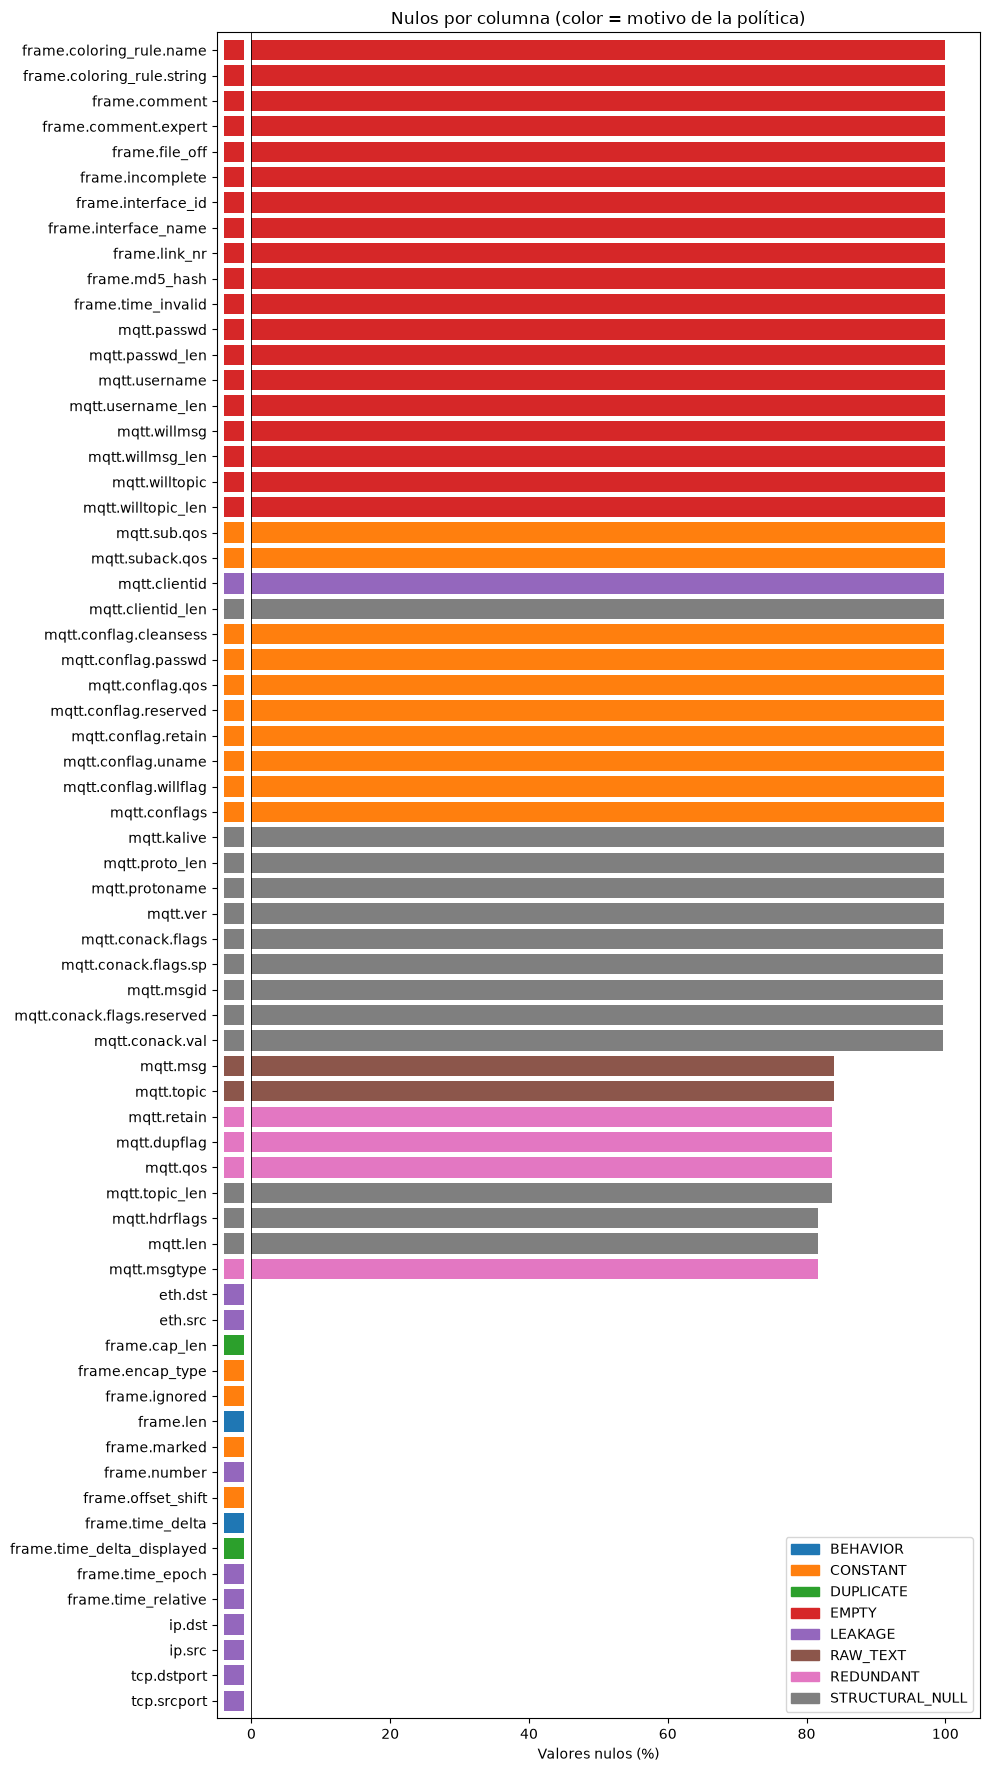

In [14]:
column_policy, policy_evidence = build_column_policy(df_captured)
display(column_policy)
display(column_policy.groupby(['acción', 'motivo']).size().rename('columnas').to_frame())
eda.plot_policy_summary(column_policy)
eda.plot_missingness(missingness, column_policy)

### 2.7 Aplicar la política

Se eliminan las columnas DROP, salvo `frame.time_epoch`: es `LEAKAGE` como
feature, pero se conserva como **contexto** para ordenar los frames de cada
ventana. Las columnas DERIVE siguen en el DataFrame porque la ingeniería de
features las lee; la matriz del modelo usa solo `FEATURE_COLUMNS`. Las claves
`_connection` y `_direction` ya se construyeron en la carga, así que IP, MAC y
`client_id` no hacen falta.

In [15]:
CONTEXT_COLUMNS = ['frame.time_epoch']
df_raw, dropped_columns = apply_column_policy(df_captured, column_policy, CONTEXT_COLUMNS)
print(f'Columnas eliminadas: {len(dropped_columns)}')
print('Columnas restantes:', sorted(c for c in df_raw.columns if not c.startswith('_')))

Columnas eliminadas: 51
Columnas restantes: ['frame.len', 'frame.time_delta', 'frame.time_epoch', 'mqtt.clientid_len', 'mqtt.hdrflags', 'mqtt.kalive', 'mqtt.len', 'mqtt.msg', 'mqtt.proto_len', 'mqtt.protoname', 'mqtt.topic', 'mqtt.topic_len', 'mqtt.ver', 'tcp.dstport', 'tcp.srcport', 'type']


In [16]:
NETWORK_RAW = ['frame.len', 'frame.time_delta']
MQTT_NUMERIC_COLUMNS = ['mqtt.hdrflags', 'mqtt.len', 'mqtt.topic_len']


def build_network_features(X_full):
    """Network/transport features without raw ports or capture timestamps."""
    base = X_full[NETWORK_RAW].apply(pd.to_numeric, errors='coerce').fillna(NAN_FILL).copy()
    base['fe_bytes_per_sec'] = base['frame.len'] / (base['frame.time_delta'] + 1e-6)
    dst = pd.to_numeric(X_full['tcp.dstport'], errors='coerce')
    src = pd.to_numeric(X_full['tcp.srcport'], errors='coerce')
    base['fe_is_standard_mqtt_port'] = dst.isin([1883, 8883]).astype(int)
    base['fe_is_broker_to_client'] = src.isin([1883, 8883]).astype(int)
    base['fe_log_len'] = np.log1p(base['frame.len'])
    return base


def build_mqtt_features(df):
    """Compact MQTT matrix without identifiers, raw ports, or capture timestamps."""
    result = build_network_features(df)

    def number(value):
        if isinstance(value, str) and value.lower().startswith('0x'):
            try:
                return int(value, 16)
            except ValueError:
                return np.nan
        return value

    for col in MQTT_NUMERIC_COLUMNS:
        series = df[col] if col in df else pd.Series(np.nan, index=df.index)
        result[col] = pd.to_numeric(series.map(number), errors='coerce').fillna(NAN_FILL)
    msg = df['mqtt.msg'] if 'mqtt.msg' in df else pd.Series(None, index=df.index, dtype=object)
    topic = df['mqtt.topic'] if 'mqtt.topic' in df else pd.Series(None, index=df.index, dtype=object)
    result['fe_msg_entropy'] = msg.apply(entropy)
    result['fe_topic_entropy'] = topic.apply(entropy)
    result['fe_topic_depth'] = topic.apply(
        lambda value: 0 if pd.isna(value) or not str(value) else str(value).count('/') + 1)
    result['fe_payload_ratio'] = result['mqtt.len'].clip(lower=0) / (
        result['frame.len'].clip(lower=0) + 1e-5)
    return result.replace([np.inf, -np.inf], NAN_FILL).fillna(NAN_FILL)


def build_feature_matrix(df):
    """Final matrix in FEATURE_COLUMNS order."""
    return build_mqtt_features(df)[FEATURE_COLUMNS]


In [17]:
X = build_feature_matrix(df_raw)
le_target = LabelEncoder().fit(df_raw[TARGET_COL])
CLASS_NAMES = le_target.classes_
y = pd.Series(le_target.transform(df_raw[TARGET_COL]), index=df_raw.index)
normal_idx = int(le_target.transform(['normal'])[0])
assert all(pd.api.types.is_numeric_dtype(X[col]) for col in X)
assert np.isfinite(X.to_numpy()).all()
print(f'Final matrix: {X.shape}; classes: {list(CLASS_NAMES)}')
print(f'Retained raw columns ({len(RAW_FEATURE_COLUMNS)}):', RAW_FEATURE_COLUMNS)
print(f'Engineered columns ({len(ENGINEERED_FEATURE_COLUMNS)}):',
      ENGINEERED_FEATURE_COLUMNS)
feature_catalog = pd.DataFrame({
    'column': FEATURE_COLUMNS,
    'source': [
        'retained raw' if name in RAW_FEATURE_COLUMNS else 'feature engineering'
        for name in FEATURE_COLUMNS
    ],
})
print('\nCatalog of the 13 features in training order:')
print(feature_catalog.to_string(index=False))
print('\nPreview of the final matrix:')
print(X.head())


Final matrix: (257457, 13); classes: ['DoS', 'normal']
Retained raw columns (5): ['frame.len', 'frame.time_delta', 'mqtt.hdrflags', 'mqtt.len', 'mqtt.topic_len']
Engineered columns (8): ['fe_bytes_per_sec', 'fe_is_standard_mqtt_port', 'fe_is_broker_to_client', 'fe_log_len', 'fe_msg_entropy', 'fe_topic_entropy', 'fe_topic_depth', 'fe_payload_ratio']

Catalog of the 13 features in training order:
                  column              source
               frame.len        retained raw
        frame.time_delta        retained raw
        fe_bytes_per_sec feature engineering
fe_is_standard_mqtt_port feature engineering
  fe_is_broker_to_client feature engineering
              fe_log_len feature engineering
           mqtt.hdrflags        retained raw
                mqtt.len        retained raw
          mqtt.topic_len        retained raw
          fe_msg_entropy feature engineering
        fe_topic_entropy feature engineering
          fe_topic_depth feature engineering
        fe_payloa

### 2.8 Alcance MQTT (1883/8883): `df_scope`

El experimento A/B se hace sobre frames IPv4/TCP con puerto 1883 u 8883 en
origen o destino. Se filtra por puerto, no por capa MQTT, para conservar los
SYN/ACK de las conexiones MQTT (que el agente también ve) y el ~14 % de frames
DoS sin capa MQTT.

`df_scope` sale de `df_raw`, así que ya tiene aplicada la política de columnas y
conserva `_connection`, `_direction`, `_capture` y `frame.time_epoch`. `df_raw`
no se modifica. Los datos son `DoS.csv` completo más el normal de `MitM.csv` e
`Intrusion.csv`.

In [18]:
scope_ports = df_raw[['tcp.srcport', 'tcp.dstport']].apply(
    pd.to_numeric, errors='coerce')
scope_mask = scope_ports.isin([1883, 8883]).any(axis=1)
df_scope = df_raw.loc[scope_mask].copy()
SCOPE_NORMAL_CAPTURES = sorted(
    df_scope.loc[df_scope[TARGET_COL].eq('normal'), '_capture'].unique())

print(f'df_scope: {df_scope.shape}')
display(pd.crosstab(df_scope['_capture'], df_scope[TARGET_COL], margins=True))
print('Conexiones por clase:',
      df_scope.groupby(TARGET_COL)['_connection'].nunique().to_dict())
print('Conexiones normales por captura:',
      df_scope.loc[df_scope[TARGET_COL].eq('normal')]
      .groupby('_capture')['_connection'].nunique().to_dict())
print('Capturas normales en el alcance:', SCOPE_NORMAL_CAPTURES)
if len(SCOPE_NORMAL_CAPTURES) < 3:
    print('ADVERTENCIA: falta normal de alguna captura; se documentará al elegir folds.')

df_scope: (61654, 21)


type,DoS,normal,All
_capture,,,
DoS,45330,969,46299
Intrusion,0,7700,7700
MitM,0,7655,7655
All,45330,16324,61654


Conexiones por clase: {'DoS': 886, 'normal': 432}
Conexiones normales por captura: {'DoS': 41, 'Intrusion': 368, 'MitM': 23}
Capturas normales en el alcance: ['DoS', 'Intrusion', 'MitM']


### 2.9 Comparación A (MQTT en claro) vs B (solo TCP)

**Objetivo.** Decidir si el modelo DoS necesita los campos MQTT (solo existen en
MQTT en claro) o si basta TCP/IP (observable también con MQTTS). A es el set
actual de 13 features; B son las 12 features de `tcp_features.py`.

**Modelo.** Un XGBoost con los mismos hiperparámetros fijos para A y B, sin
Optuna, con `sample_weight` balanceado. No se usan los modelos de las secciones
5–7.

**División.** `StratifiedGroupKFold` por `_connection`. Se intentan 5 folds; si
algún fold no tiene normal de las tres capturas (o no tiene ambas clases), se
reduce el número de folds y se documenta. El *leave-one-capture-out* del normal
solo se ejecuta si 2.3.4 lo exige.

**Línea base.** La mejor regla trivial dentro de `df_scope` (por ejemplo
"cliente → broker ⇒ DoS"). Un set que no la supere no aporta nada.

**Métricas.** Macro-F1, balanced accuracy, ROC-AUC y recall de DoS, media ± std
por fold. Además, tasa de falsos positivos por captura de origen del normal
(DoS, MitM, Intrusion) e importancia de features.

**Criterio.** A es la opción por defecto. B solo se elige si su macro-F1 queda a
≤ 0.03 de A, supera la línea base y no aumenta los FP en ninguna captura de
origen. Si B pierde más, se documenta que A solo vale para MQTT en claro.

Además se evalúa **A' = B + las features MQTT de A** (mismo ventaneo TCP).
A' no es una opción del plan: sirve para aislar cuánto aportan realmente las
features MQTT cuando ya están las ventanas TCP. Si A' no supera a B, la
diferencia A/B viene de la agregación temporal, no de MQTT.

Al final, 2.9.5 repite A, B y A' sobre **todo** el tráfico (sin filtro de
puerto) como diagnóstico: así se ve cuánto de la ventaja de A viene del normal
no-MQTT y no se descarta A por la distribución.

In [19]:
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score
from data_preprocessing.tcp_features import TCP_FEATURE_COLUMNS, build_tcp_features

RUN_TLS_SENSITIVITY = True
RUN_FULL_TRAFFIC_DIAGNOSTIC = True

SCOPE_METRIC_COLUMNS = [
    'macro_f1', 'balanced_accuracy', 'roc_auc',
    'dos_recall', 'dos_precision', 'normal_recall',
    'fp_DoS', 'fp_MitM', 'fp_Intrusion',
]

scope_labels = df_scope[TARGET_COL].eq('DoS').astype(int).to_numpy()
scope_groups = pd.factorize(df_scope['_connection'], sort=False)[0]
scope_captures = df_scope['_capture'].to_numpy()
scope_mqtt_layer = df_scope['mqtt.hdrflags'].notna().to_numpy()

X_scope_a = build_feature_matrix(df_scope)
X_scope_b = build_tcp_features(df_scope)
SCOPE_A_PRIME_COLUMNS = [
    column for column in X_scope_a.columns
    if column not in X_scope_b.columns
]
X_scope_ap = pd.concat(
    [X_scope_b, X_scope_a[SCOPE_A_PRIME_COLUMNS]], axis=1)
assert list(X_scope_a.columns) == FEATURE_COLUMNS
assert list(X_scope_b.columns) == TCP_FEATURE_COLUMNS
assert np.isfinite(X_scope_a.to_numpy()).all()
assert np.isfinite(X_scope_b.to_numpy()).all()
assert np.isfinite(X_scope_ap.to_numpy()).all()
print(f'A: {X_scope_a.shape[1]} features; B: {X_scope_b.shape[1]} features; '
      f"A': {X_scope_ap.shape[1]} features; frames: {len(df_scope)}")
print("Features que A' añade a B:", SCOPE_A_PRIME_COLUMNS)

SCOPE_XGB_PARAMS = {
    'n_estimators': 300,
    'learning_rate': 0.05,
    'max_depth': 4,
    'min_child_weight': 2.0,
    'subsample': 0.9,
    'colsample_bytree': 0.9,
    'reg_lambda': 1.0,
    'objective': 'binary:logistic',
    'tree_method': 'hist',
    'random_state': SEED,
    'eval_metric': 'logloss',
    'n_jobs': -1,
}


def make_scope_model():
    return XGBClassifier(**SCOPE_XGB_PARAMS)


def find_grouped_splits(features, labels, groups, captures,
                        required_normal_captures, max_splits=5):
    for n_splits in range(max_splits, 1, -1):
        splitter = StratifiedGroupKFold(
            n_splits=n_splits, shuffle=True, random_state=SEED)
        splits = list(splitter.split(features, labels, groups=groups))
        valid = True
        for train_idx, test_idx in splits:
            for indices in (train_idx, test_idx):
                if len(np.unique(labels[indices])) < 2:
                    valid = False
                    break
                normal_captures = set(
                    captures[indices][labels[indices] == 0])
                if not required_normal_captures.issubset(normal_captures):
                    valid = False
                    break
            if not valid:
                break
        if valid:
            return n_splits, splits
    raise ValueError(
        'No hay folds agrupados con ambas clases y normal de todas las capturas. '
        f'Capturas requeridas: {sorted(required_normal_captures)}')


SCOPE_N_SPLITS, SCOPE_SPLITS = find_grouped_splits(
    X_scope_a, scope_labels, scope_groups, scope_captures,
    set(SCOPE_NORMAL_CAPTURES), max_splits=5)
print(f'Folds del alcance: {SCOPE_N_SPLITS}')
for fold_id, (train_idx, test_idx) in enumerate(SCOPE_SPLITS):
    print(f'  fold {fold_id}: train={len(train_idx)} test={len(test_idx)} '
          f'normal_test={dict(pd.Series(scope_captures[test_idx][scope_labels[test_idx] == 0]).value_counts())}')


def trivial_rule_table(frame, labels):
    ports = frame[['tcp.srcport', 'tcp.dstport']].apply(
        pd.to_numeric, errors='coerce')
    client_to_broker = ports['tcp.dstport'].isin([1883, 8883]).astype(int).to_numpy()
    broker_to_client = ports['tcp.srcport'].isin([1883, 8883]).astype(int).to_numpy()
    has_mqtt = frame['mqtt.hdrflags'].notna().astype(int).to_numpy()
    rules = {
        'siempre normal': np.zeros(len(labels), dtype=int),
        'siempre DoS': np.ones(len(labels), dtype=int),
        'cliente -> broker': client_to_broker,
        'broker -> cliente': broker_to_client,
        'capa MQTT': has_mqtt,
        'cliente -> broker o capa MQTT': np.maximum(client_to_broker, has_mqtt),
    }
    rows = []
    for name, prediction in rules.items():
        rows.append({
            'regla': name,
            'macro_f1': f1_score(labels, prediction, average='macro', zero_division=0),
            'balanced_accuracy': balanced_accuracy_score(labels, prediction),
            'dos_recall': recall_score(labels, prediction, pos_label=1, zero_division=0),
            'dos_precision': precision_score(labels, prediction, pos_label=1, zero_division=0),
        })
    return pd.DataFrame(rows).sort_values(
        'macro_f1', ascending=False).reset_index(drop=True)


scope_baseline = trivial_rule_table(df_scope, scope_labels)
display(scope_baseline.round(4))
SCOPE_BASELINE_NAME = str(scope_baseline.iloc[0]['regla'])
SCOPE_BASELINE_MACRO_F1 = float(scope_baseline.iloc[0]['macro_f1'])
print(f'Línea base del alcance: {SCOPE_BASELINE_NAME} '
      f'(macro-F1={SCOPE_BASELINE_MACRO_F1:.4f})')


def classification_metrics(labels, prediction, probability):
    return {
        'macro_f1': float(f1_score(labels, prediction, average='macro', zero_division=0)),
        'balanced_accuracy': float(balanced_accuracy_score(labels, prediction)),
        'roc_auc': float(roc_auc_score(labels, probability)),
        'dos_recall': float(recall_score(labels, prediction, pos_label=1, zero_division=0)),
        'dos_precision': float(precision_score(labels, prediction, pos_label=1, zero_division=0)),
        'normal_recall': float(recall_score(labels, prediction, pos_label=0, zero_division=0)),
    }


def false_positive_by_capture(labels, prediction, captures):
    normal = labels == 0
    result = {}
    for capture in sorted(set(captures[normal])):
        mask = normal & (captures == capture)
        result[f'fp_{capture}'] = float(prediction[mask].mean()) if mask.any() else np.nan
    return result


def compare_feature_sets(feature_sets, labels, groups, captures, splits):
    rows = []
    importances = {}
    fitted = {}
    for fold_id, (train_idx, test_idx) in enumerate(splits):
        for name, features in feature_sets.items():
            model = make_scope_model()
            model.fit(
                features.iloc[train_idx], labels[train_idx],
                sample_weight=compute_sample_weight('balanced', labels[train_idx]))
            prediction = model.predict(features.iloc[test_idx])
            probability = model.predict_proba(features.iloc[test_idx])[:, 1]
            row = {
                'set': name, 'fold': fold_id,
                **classification_metrics(labels[test_idx], prediction, probability),
                **false_positive_by_capture(labels[test_idx], prediction, captures[test_idx]),
            }
            rows.append(row)
            importances.setdefault(name, []).append(
                pd.Series(model.feature_importances_, index=features.columns))
            fitted[(name, fold_id)] = (model, test_idx)
    return pd.DataFrame(rows), importances, fitted

A: 13 features; B: 12 features; A': 20 features; frames: 61654
Features que A' añade a B: ['fe_bytes_per_sec', 'mqtt.hdrflags', 'mqtt.len', 'mqtt.topic_len', 'fe_msg_entropy', 'fe_topic_entropy', 'fe_topic_depth', 'fe_payload_ratio']
Folds del alcance: 5
  fold 0: train=49320 test=12334 normal_test={'MitM': np.int64(2190), 'Intrusion': np.int64(840), 'DoS': np.int64(234)}
  fold 1: train=49324 test=12330 normal_test={'Intrusion': np.int64(3052), 'MitM': np.int64(120), 'DoS': np.int64(93)}
  fold 2: train=49324 test=12330 normal_test={'MitM': np.int64(1923), 'Intrusion': np.int64(1121), 'DoS': np.int64(221)}
  fold 3: train=49323 test=12331 normal_test={'Intrusion': np.int64(2093), 'MitM': np.int64(836), 'DoS': np.int64(337)}
  fold 4: train=49325 test=12329 normal_test={'MitM': np.int64(2586), 'Intrusion': np.int64(594), 'DoS': np.int64(84)}


,regla,macro_f1,balanced_accuracy,dos_recall,dos_precision
0,capa MQTT,0.6911,0.6849,0.8613,0.8295
1,cliente -> broker,0.6790,0.6648,0.8993,0.8142
2,cliente -> broker o capa MQTT,0.6025,0.5950,0.9063,0.7784
3,siempre DoS,0.4237,0.5000,1.0000,0.7352
4,broker -> cliente,0.2203,0.3352,0.1007,0.3938
5,siempre normal,0.2093,0.5000,0.0000,0.0000


Línea base del alcance: capa MQTT (macro-F1=0.6911)


In [20]:
scope_folds, scope_importance, scope_models = compare_feature_sets(
    {'A': X_scope_a, 'B': X_scope_b, "A'": X_scope_ap},
    scope_labels, scope_groups, scope_captures, SCOPE_SPLITS)
display(scope_folds.round(4))

,set,fold,macro_f1,balanced_accuracy,roc_auc,dos_recall,dos_precision,normal_recall,fp_DoS,fp_Intrusion,fp_MitM
0,A,0,0.9770,0.9842,0.9986,0.9792,0.9961,0.9893,0.0385,0.0119,0.0073
1,B,0,0.9946,0.9957,0.9999,0.9959,0.9983,0.9954,0.0128,0.0000,0.0055
2,A',0,0.9966,0.9977,0.9999,0.9969,0.9994,0.9985,0.0128,0.0012,0.0005
3,A,1,0.9798,0.9844,0.9987,0.9838,0.9945,0.9850,0.1290,0.0115,0.0167
4,B,1,0.9966,0.9976,0.9999,0.9970,0.9993,0.9982,0.0430,0.0007,0.0000
5,A',1,0.9972,0.9980,1.0000,0.9976,0.9994,0.9985,0.0215,0.0010,0.0000
6,A,2,0.9795,0.9838,0.9985,0.9839,0.9941,0.9838,0.0588,0.0089,0.0156
7,B,2,0.9957,0.9961,0.9999,0.9974,0.9981,0.9948,0.0181,0.0027,0.0052
8,A',2,0.9971,0.9978,1.0000,0.9977,0.9992,0.9979,0.0136,0.0027,0.0005
9,A,3,0.9793,0.9852,0.9989,0.9820,0.9957,0.9884,0.0831,0.0043,0.0012


In [21]:
scope_summary = scope_folds.groupby('set')[SCOPE_METRIC_COLUMNS].agg(['mean', 'std'])
scope_summary.columns = [f'{metric}_{stat}' for metric, stat in scope_summary.columns]
display(scope_summary.round(4))

scope_means = scope_folds.groupby('set')[SCOPE_METRIC_COLUMNS].mean()
print('Media por set:')
display(scope_means.round(4))

for name, frames in scope_importance.items():
    average = pd.concat(frames, axis=1).mean(axis=1).sort_values(ascending=False)
    print(f'\nImportancia media ({name})')
    display(average.head(10).to_frame('importance').round(4))
    print(f'Peso de la top feature ({name}): {average.iloc[0] / average.sum():.1%}')

,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std,dos_recall_mean,dos_recall_std,dos_precision_mean,dos_precision_std,normal_recall_mean,normal_recall_std,fp_DoS_mean,fp_DoS_std,fp_MitM_mean,fp_MitM_std,fp_Intrusion_mean,fp_Intrusion_std
set,,,,,,,,,,,,,,,,,,
A,0.9778,0.0027,0.9836,0.0020,0.9987,0.0002,0.9813,0.0028,0.9948,0.0010,0.9858,0.0028,0.0881,0.0414,0.0107,0.0064,0.0114,0.0058
A',0.9973,0.0005,0.9979,0.0002,0.9999,0.0000,0.9979,0.0007,0.9992,0.0003,0.9979,0.0008,0.0244,0.0142,0.0005,0.0004,0.0014,0.0008
B,0.9962,0.0010,0.9969,0.0009,0.9999,0.0000,0.9972,0.0008,0.9987,0.0005,0.9965,0.0014,0.0344,0.0236,0.0023,0.0028,0.0011,0.0011


Media por set:


,macro_f1,balanced_accuracy,roc_auc,dos_recall,dos_precision,normal_recall,fp_DoS,fp_MitM,fp_Intrusion
set,,,,,,,,,
A,0.9778,0.9836,0.9987,0.9813,0.9948,0.9858,0.0881,0.0107,0.0114
A',0.9973,0.9979,0.9999,0.9979,0.9992,0.9979,0.0244,0.0005,0.0014
B,0.9962,0.9969,0.9999,0.9972,0.9987,0.9965,0.0344,0.0023,0.0011



Importancia media (A)


,importance
frame.len,0.2796
fe_bytes_per_sec,0.2437
fe_log_len,0.1676
mqtt.len,0.1007
mqtt.topic_len,0.0780
frame.time_delta,0.0487
mqtt.hdrflags,0.0319
fe_is_broker_to_client,0.0186
fe_is_standard_mqtt_port,0.0161
fe_payload_ratio,0.0066


Peso de la top feature (A): 28.0%

Importancia media (B)


,importance
tcp_new_conns_5s,0.5445
frame.len,0.2224
tcp_len_std_5s,0.0962
tcp_bytes_5s,0.0363
fe_log_len,0.0220
frame.time_delta,0.0214
tcp_asymmetry_5s,0.0206
tcp_iat_std_5s,0.0124
tcp_iat,0.0094
fe_is_broker_to_client,0.0090


Peso de la top feature (B): 54.4%

Importancia media (A')


,importance
tcp_new_conns_5s,0.3032
fe_log_len,0.2478
mqtt.topic_len,0.1218
mqtt.len,0.0937
fe_bytes_per_sec,0.0706
tcp_len_std_5s,0.0596
frame.len,0.0405
tcp_iat_std_5s,0.0134
tcp_bytes_5s,0.0130
tcp_asymmetry_5s,0.0111


Peso de la top feature (A'): 30.3%


In [22]:
def tls_padding_sensitivity(features, labels, splits, mqtt_layer,
                            padding_min=21, padding_max=40):
    rng = np.random.default_rng(SEED)
    rows = []
    for fold_id, (train_idx, test_idx) in enumerate(splits):
        model = make_scope_model()
        model.fit(
            features.iloc[train_idx], labels[train_idx],
            sample_weight=compute_sample_weight('balanced', labels[train_idx]))
        base_prediction = model.predict(features.iloc[test_idx])
        base_f1 = f1_score(labels[test_idx], base_prediction,
                           average='macro', zero_division=0)

        perturbed = features.iloc[test_idx].copy()
        mqtt_mask = mqtt_layer[test_idx]
        positions = np.where(mqtt_mask)[0]
        if len(positions):
            padding = rng.uniform(
                padding_min, padding_max + 1, size=len(positions))
            frame_len = perturbed['frame.len'].to_numpy().copy()
            frame_len[positions] += padding
            perturbed['frame.len'] = frame_len
            perturbed['fe_log_len'] = np.log1p(frame_len)

        tls_prediction = model.predict(perturbed)
        tls_f1 = f1_score(labels[test_idx], tls_prediction,
                          average='macro', zero_division=0)
        rows.append({
            'fold': fold_id,
            'macro_f1_base': float(base_f1),
            'macro_f1_tls': float(tls_f1),
            'caida': float(base_f1 - tls_f1),
            'frames_mqtt_perturbados': int(len(positions)),
        })
    return pd.DataFrame(rows)


if RUN_TLS_SENSITIVITY:
    tls_sensitivity = tls_padding_sensitivity(
        X_scope_b, scope_labels, SCOPE_SPLITS, scope_mqtt_layer)
    display(tls_sensitivity.round(4))
    print('Caída media de B con padding TLS: '
          f"{tls_sensitivity['caida'].mean():.4f}")
else:
    print('Sensibilidad TLS omitida (RUN_TLS_SENSITIVITY=False).')

,fold,macro_f1_base,macro_f1_tls,caida,frames_mqtt_perturbados
0,0,0.9946,0.9934,0.0011,9045
1,1,0.9966,0.9966,-0.0000,9454
2,2,0.9957,0.9958,-0.0001,9473
3,3,0.9971,0.9960,0.0010,9613
4,4,0.9970,0.9935,0.0035,9484


Caída media de B con padding TLS: 0.0011


In [23]:
a_mean = scope_means.loc['A']
b_mean = scope_means.loc['B']
ap_mean = scope_means.loc["A'"]
fp_columns = [column for column in SCOPE_METRIC_COLUMNS if column.startswith('fp_')]

b_close = (a_mean['macro_f1'] - b_mean['macro_f1']) <= 0.03
b_beats_baseline = b_mean['macro_f1'] >= SCOPE_BASELINE_MACRO_F1
b_fp_ok = bool((b_mean[fp_columns] <= a_mean[fp_columns] + 1e-12).all())
mqtt_gain = ap_mean['macro_f1'] - b_mean['macro_f1']

print(f'A macro-F1: {a_mean["macro_f1"]:.4f}')
print(f'B macro-F1: {b_mean["macro_f1"]:.4f} '
      f'(diferencia A-B: {a_mean["macro_f1"] - b_mean["macro_f1"]:+.4f})')
print(f"A' (B + MQTT) macro-F1: {ap_mean['macro_f1']:.4f} "
      f'(ganancia sobre B: {mqtt_gain:+.4f})')
print(f'Línea base: {SCOPE_BASELINE_NAME} = {SCOPE_BASELINE_MACRO_F1:.4f}')
print('B a ≤0.03 de A:', b_close)
print('B supera la línea base:', b_beats_baseline)
print('B no empeora FP por captura:', b_fp_ok)
display(pd.DataFrame({
    'A': a_mean[fp_columns],
    'B': b_mean[fp_columns],
    "A'": ap_mean[fp_columns],
}).round(4))

if b_close and b_beats_baseline and b_fp_ok:
    print('DECISIÓN: B (solo TCP) cumple el criterio; es el candidato para MQTTS.')
else:
    print('DECISIÓN: A (MQTT en claro) se mantiene; B no cumple el criterio. '
          'Documentar que A solo vale para MQTT en claro.')

if mqtt_gain > 0.03:
    print("A' supera a B por más de 0.03: las features MQTT sí aportan de forma "
          'material y B+MQTT (A\') debe considerarse un tercer candidato.')
else:
    print("A' no supera a B por más de 0.03: una vez están las ventanas TCP, "
          'las features MQTT no aportan de forma material. La brecha A/B viene '
          'de la agregación temporal, no de MQTT.')

b_importance = pd.concat(scope_importance['B'], axis=1).mean(axis=1).sort_values(
    ascending=False)
b_top_share = b_importance.iloc[0] / b_importance.sum()
print(f"Feature dominante de B: {b_importance.index[0]} "
      f"({b_top_share:.1%} de la importancia media).")
if b_top_share > 0.50:
    print('ADVERTENCIA: una sola feature domina B. Con un solo ataque DoS grabado, '
          'B puede estar aprendiendo la herramienta/conexiones del ataque, no DoS '
          'en general. Validar con otra captura antes de reemplazar A.')

if NEEDS_LOCO:
    print('\nLeave-one-capture-out del normal (exigido por 2.3.4):')
    loco_rows = []
    for held_out in sorted(set(scope_captures[scope_labels == 0])):
        train_mask = ~((scope_labels == 0) & (scope_captures == held_out))
        test_mask = (scope_labels == 0) & (scope_captures == held_out)
        train_idx = np.where(train_mask)[0]
        test_idx = np.where(test_mask)[0]
        for name, features in {'A': X_scope_a, 'B': X_scope_b,
                               "A'": X_scope_ap}.items():
            model = make_scope_model()
            model.fit(
                features.iloc[train_idx], scope_labels[train_idx],
                sample_weight=compute_sample_weight('balanced', scope_labels[train_idx]))
            prediction = model.predict(features.iloc[test_idx])
            loco_rows.append({
                'set': name,
                'captura_held_out': held_out,
                'normal_recall': float((prediction == 0).mean()),
                'fp_rate': float((prediction == 1).mean()),
                'samples': int(len(test_idx)),
            })
    display(pd.DataFrame(loco_rows).round(4))
else:
    print('No se ejecuta leave-one-capture-out: 2.3.4 encontró normal concurrente suficiente.')

A macro-F1: 0.9778
B macro-F1: 0.9962 (diferencia A-B: -0.0184)
A' (B + MQTT) macro-F1: 0.9973 (ganancia sobre B: +0.0011)
Línea base: capa MQTT = 0.6911
B a ≤0.03 de A: True
B supera la línea base: True
B no empeora FP por captura: True


,A,B,A'
fp_DoS,0.0881,0.0344,0.0244
fp_MitM,0.0107,0.0023,0.0005
fp_Intrusion,0.0114,0.0011,0.0014


DECISIÓN: B (solo TCP) cumple el criterio; es el candidato para MQTTS.
A' no supera a B por más de 0.03: una vez están las ventanas TCP, las features MQTT no aportan de forma material. La brecha A/B viene de la agregación temporal, no de MQTT.
Feature dominante de B: tcp_new_conns_5s (54.4% de la importancia media).
ADVERTENCIA: una sola feature domina B. Con un solo ataque DoS grabado, B puede estar aprendiendo la herramienta/conexiones del ataque, no DoS en general. Validar con otra captura antes de reemplazar A.
No se ejecuta leave-one-capture-out: 2.3.4 encontró normal concurrente suficiente.


#### 2.9.5 Diagnóstico: A y B sobre todo el tráfico

La decisión anterior es sobre `df_scope`, pero A puede rendir distinto cuando
también ve el normal no-MQTT. Esta comparación repite el mismo protocolo sobre
`df_raw` completo (todos los frames IPv4/TCP), solo como diagnóstico. Si A cae
mucho al pasar a `df_scope`, parte de su ventaja venía de "normal no-MQTT vs DoS
MQTT"; si se mantiene, A también separa dentro de MQTT en claro. Se incluye A'
para ver si las features MQTT aportan algo sobre las ventanas TCP en todo el
tráfico, no solo en el alcance.

In [24]:
if RUN_FULL_TRAFFIC_DIAGNOSTIC:
    full_labels = df_raw[TARGET_COL].eq('DoS').astype(int).to_numpy()
    full_groups = pd.factorize(df_raw['_connection'], sort=False)[0]
    full_captures = df_raw['_capture'].to_numpy()
    full_normal_captures = set(
        df_raw.loc[df_raw[TARGET_COL].eq('normal'), '_capture'].unique())
    X_full_b = build_tcp_features(df_raw)
    full_extra = [column for column in X.columns if column not in X_full_b.columns]
    X_full_ap = pd.concat([X_full_b, X[full_extra]], axis=1)

    full_n_splits, full_splits = find_grouped_splits(
        X, full_labels, full_groups, full_captures,
        full_normal_captures, max_splits=5)
    print(f'Folds sobre todo el tráfico: {full_n_splits}')

    full_baseline = trivial_rule_table(df_raw, full_labels)
    display(full_baseline.round(4))

    full_folds, full_importance, _ = compare_feature_sets(
        {'A': X, 'B': X_full_b, "A'": X_full_ap},
        full_labels, full_groups, full_captures, full_splits)
    full_means = full_folds.groupby('set')[SCOPE_METRIC_COLUMNS].mean()
    display(full_means.round(4))

    print('A, B y A\' en todo el tráfico vs el alcance MQTT:')
    display(pd.DataFrame({
        'todo el tráfico': full_means.loc['A'],
        'alcance A': scope_means.loc['A'],
        'alcance B': scope_means.loc['B'],
        "alcance A'": scope_means.loc["A'"],
    }).round(4))
    full_gain = full_means.loc["A'"]['macro_f1'] - full_means.loc['B']['macro_f1']
    print(f"Ganancia de A' sobre B en todo el tráfico: {full_gain:+.4f}. "
          'Si la caída de A al pasar al alcance es grande, su ventaja dependía '
          'del normal no-MQTT; si A\' apenas mejora a B, MQTT no aporta sobre '
          'las ventanas TCP.')
else:
    print('Diagnóstico sobre todo el tráfico omitido (RUN_FULL_TRAFFIC_DIAGNOSTIC=False).')

Folds sobre todo el tráfico: 5


,regla,macro_f1,balanced_accuracy,dos_recall,dos_precision
0,cliente -> broker,0.9101,0.9264,0.8968,0.8142
1,capa MQTT,0.9049,0.9105,0.8589,0.8295
2,cliente -> broker o capa MQTT,0.8989,0.9243,0.9037,0.7784
3,broker -> cliente,0.5277,0.5336,0.1004,0.3938
4,siempre normal,0.4516,0.5000,0.0000,0.0000
5,siempre DoS,0.1501,0.5000,1.0000,0.1766


,macro_f1,balanced_accuracy,roc_auc,dos_recall,dos_precision,normal_recall,fp_DoS,fp_MitM,fp_Intrusion
set,,,,,,,,,
A,0.9915,0.9950,0.9993,0.9949,0.9774,0.9950,0.0043,0.0046,0.0064
A',0.9984,0.9985,0.9999,0.9977,0.9969,0.9993,0.0019,0.0003,0.0006
B,0.9981,0.9984,0.9999,0.9976,0.9963,0.9992,0.0022,0.0005,0.0006


A, B y A' en todo el tráfico vs el alcance MQTT:


,todo el tráfico,alcance A,alcance B,alcance A'
macro_f1,0.9915,0.9778,0.9962,0.9973
balanced_accuracy,0.9950,0.9836,0.9969,0.9979
roc_auc,0.9993,0.9987,0.9999,0.9999
dos_recall,0.9949,0.9813,0.9972,0.9979
dos_precision,0.9774,0.9948,0.9987,0.9992
normal_recall,0.9950,0.9858,0.9965,0.9979
fp_DoS,0.0043,0.0881,0.0344,0.0244
fp_MitM,0.0046,0.0107,0.0023,0.0005
fp_Intrusion,0.0064,0.0114,0.0011,0.0014


Ganancia de A' sobre B en todo el tráfico: +0.0002. Si la caída de A al pasar al alcance es grande, su ventaja dependía del normal no-MQTT; si A' apenas mejora a B, MQTT no aporta sobre las ventanas TCP.


### 2.10 Ablación sobre todo el tráfico: B sin `tcp_new_conns_5s`

`tcp_new_conns_5s` concentró el 54,4 % de la importancia de B en el alcance. Esta
sección repite la comparación sobre **todo el tráfico** (`df_raw`) y quita esa
feature **solo a B**. A y A' se mantienen exactamente como en 2.9.5 y se usan como
referencia. El objetivo es medir cuánto depende B de esa señal y si, sin ella,
sigue superando a A y queda cerca de A'.

Se reutilizan las mismas funciones, folds agrupados por conexión, modelo XGBoost
y métricas de 2.9. La ablación no sustituye la validación con otra captura DoS.

In [25]:
ablation_labels = df_raw[TARGET_COL].eq('DoS').astype(int).to_numpy()
ablation_groups = pd.factorize(df_raw['_connection'], sort=False)[0]
ablation_captures = df_raw['_capture'].to_numpy()
ablation_normal_captures = set(
    df_raw.loc[df_raw[TARGET_COL].eq('normal'), '_capture'].unique())

X_ablation_a = X
X_ablation_b = build_tcp_features(df_raw)
X_ablation_b_no_conns = X_ablation_b.drop(columns=['tcp_new_conns_5s'])
ablation_extra = [
    column for column in X_ablation_a.columns
    if column not in X_ablation_b.columns
]
X_ablation_ap = pd.concat(
    [X_ablation_b, X_ablation_a[ablation_extra]], axis=1)

assert 'tcp_new_conns_5s' not in X_ablation_b_no_conns.columns
for name, matrix in (('A', X_ablation_a), ('B', X_ablation_b),
                     ("A'", X_ablation_ap),
                     ('B sin tcp_new_conns_5s', X_ablation_b_no_conns)):
    assert np.isfinite(matrix.to_numpy()).all(), name
print(f"A: {X_ablation_a.shape[1]} features; B: {X_ablation_b.shape[1]}; "
      f"A': {X_ablation_ap.shape[1]}; B sin tcp_new_conns_5s: "
      f"{X_ablation_b_no_conns.shape[1]}")

ablation_n_splits, ablation_splits = find_grouped_splits(
    X_ablation_b, ablation_labels, ablation_groups, ablation_captures,
    ablation_normal_captures, max_splits=5)
print(f'Folds de la ablación sobre todo el tráfico: {ablation_n_splits}')

ablation_folds, ablation_importance, _ = compare_feature_sets(
    {'A': X_ablation_a,
     'B': X_ablation_b,
     "A'": X_ablation_ap,
     'B sin tcp_new_conns_5s': X_ablation_b_no_conns},
    ablation_labels, ablation_groups, ablation_captures, ablation_splits)
display(ablation_folds.round(4))

A: 13 features; B: 12; A': 20; B sin tcp_new_conns_5s: 11
Folds de la ablación sobre todo el tráfico: 5


,set,fold,macro_f1,balanced_accuracy,roc_auc,dos_recall,dos_precision,normal_recall,fp_DoS,fp_Intrusion,fp_MitM
0,A,0,0.9954,0.9963,0.9995,0.9947,0.9901,0.9979,0.0038,0.0041,0.0004
1,B,0,0.9982,0.9983,0.9998,0.9973,0.9968,0.9993,0.0025,0.0007,0.0002
2,A',0,0.9984,0.9983,0.9998,0.9970,0.9978,0.9995,0.0015,0.0007,0.0000
3,B sin tcp_new_conns_5s,0,0.9960,0.9969,0.9998,0.9957,0.9912,0.9981,0.0034,0.0033,0.0006
4,A,1,0.9922,0.9944,0.9991,0.9927,0.9815,0.9960,0.0055,0.0087,0.0003
5,B,1,0.9983,0.9981,0.9998,0.9967,0.9978,0.9995,0.0026,0.0003,0.0000
6,A',1,0.9986,0.9984,0.9998,0.9973,0.9980,0.9996,0.0026,0.0002,0.0000
7,B sin tcp_new_conns_5s,1,0.9957,0.9956,0.9994,0.9926,0.9932,0.9985,0.0033,0.0025,0.0002
8,A,2,0.9854,0.9923,0.9986,0.9937,0.9590,0.9909,0.0084,0.0059,0.0114
9,B,2,0.9978,0.9982,0.9999,0.9974,0.9953,0.9990,0.0034,0.0006,0.0005


In [26]:
ablation_summary = ablation_folds.groupby('set')[SCOPE_METRIC_COLUMNS].agg(['mean', 'std'])
ablation_summary.columns = [f'{metric}_{stat}' for metric, stat in ablation_summary.columns]
display(ablation_summary.round(4))

ablation_means = ablation_folds.groupby('set')[SCOPE_METRIC_COLUMNS].mean()
print('Media por set:')
display(ablation_means.round(4))

ablation_table = pd.DataFrame({
    'A': ablation_means.loc['A'],
    'B': ablation_means.loc['B'],
    "A'": ablation_means.loc["A'"],
    'B sin tcp_new_conns_5s': ablation_means.loc['B sin tcp_new_conns_5s'],
}).round(4)
print('Comparación de referencia:')
display(ablation_table)

ablation_delta = pd.DataFrame({
    'B - B sin': (ablation_means.loc['B']
                  - ablation_means.loc['B sin tcp_new_conns_5s']),
    "A' - B sin": (ablation_means.loc["A'"]
                   - ablation_means.loc['B sin tcp_new_conns_5s']),
    'B sin - A': (ablation_means.loc['B sin tcp_new_conns_5s']
                  - ablation_means.loc['A']),
}).round(4)
print('Diferencias clave:')
display(ablation_delta)

importance_no_conns = pd.concat(
    ablation_importance['B sin tcp_new_conns_5s'], axis=1).mean(axis=1).sort_values(
    ascending=False)
print('Importancia media de B sin tcp_new_conns_5s:')
display(importance_no_conns.head(10).to_frame('importance').round(4))
print(f'Feature dominante sin tcp_new_conns_5s: {importance_no_conns.index[0]} '
      f'({importance_no_conns.iloc[0] / importance_no_conns.sum():.1%} de la '
      'importancia media).')

,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std,dos_recall_mean,dos_recall_std,dos_precision_mean,dos_precision_std,normal_recall_mean,normal_recall_std,fp_DoS_mean,fp_DoS_std,fp_MitM_mean,fp_MitM_std,fp_Intrusion_mean,fp_Intrusion_std
set,,,,,,,,,,,,,,,,,,
A,0.9915,0.0037,0.9950,0.0017,0.9993,0.0004,0.9949,0.0019,0.9774,0.0114,0.9950,0.0026,0.0043,0.0028,0.0046,0.0046,0.0064,0.0017
A',0.9984,0.0002,0.9985,0.0003,0.9999,0.0001,0.9977,0.0008,0.9969,0.0009,0.9993,0.0002,0.0019,0.0008,0.0003,0.0003,0.0006,0.0003
B,0.9981,0.0002,0.9984,0.0003,0.9999,0.0001,0.9976,0.0008,0.9963,0.0012,0.9992,0.0003,0.0022,0.0010,0.0005,0.0004,0.0006,0.0002
B sin tcp_new_conns_5s,0.9953,0.0007,0.9966,0.0009,0.9997,0.0002,0.9954,0.0021,0.9893,0.0030,0.9977,0.0007,0.0031,0.0020,0.0015,0.0011,0.0035,0.0010


Media por set:


,macro_f1,balanced_accuracy,roc_auc,dos_recall,dos_precision,normal_recall,fp_DoS,fp_MitM,fp_Intrusion
set,,,,,,,,,
A,0.9915,0.9950,0.9993,0.9949,0.9774,0.9950,0.0043,0.0046,0.0064
A',0.9984,0.9985,0.9999,0.9977,0.9969,0.9993,0.0019,0.0003,0.0006
B,0.9981,0.9984,0.9999,0.9976,0.9963,0.9992,0.0022,0.0005,0.0006
B sin tcp_new_conns_5s,0.9953,0.9966,0.9997,0.9954,0.9893,0.9977,0.0031,0.0015,0.0035


Comparación de referencia:


,A,B,A',B sin tcp_new_conns_5s
macro_f1,0.9915,0.9981,0.9984,0.9953
balanced_accuracy,0.9950,0.9984,0.9985,0.9966
roc_auc,0.9993,0.9999,0.9999,0.9997
dos_recall,0.9949,0.9976,0.9977,0.9954
dos_precision,0.9774,0.9963,0.9969,0.9893
normal_recall,0.9950,0.9992,0.9993,0.9977
fp_DoS,0.0043,0.0022,0.0019,0.0031
fp_MitM,0.0046,0.0005,0.0003,0.0015
fp_Intrusion,0.0064,0.0006,0.0006,0.0035


Diferencias clave:


,B - B sin,A' - B sin,B sin - A
macro_f1,0.0028,0.0030,0.0038
balanced_accuracy,0.0018,0.0020,0.0016
roc_auc,0.0002,0.0002,0.0004
dos_recall,0.0021,0.0023,0.0005
dos_precision,0.0071,0.0077,0.0119
normal_recall,0.0015,0.0017,0.0026
fp_DoS,-0.0009,-0.0012,-0.0012
fp_MitM,-0.0010,-0.0012,-0.0031
fp_Intrusion,-0.0029,-0.0029,-0.0028


Importancia media de B sin tcp_new_conns_5s:


,importance
tcp_asymmetry_5s,0.5803
fe_is_standard_mqtt_port,0.3412
frame.time_delta,0.0196
tcp_iat_std_5s,0.0126
tcp_iat,0.0100
fe_is_broker_to_client,0.0080
frame.len,0.0078
tcp_bytes_5s,0.0061
fe_log_len,0.0057
tcp_frames_5s,0.0056


Feature dominante sin tcp_new_conns_5s: tcp_asymmetry_5s (58.0% de la importancia media).


In [27]:
drop_f1 = (ablation_means.loc['B', 'macro_f1']
           - ablation_means.loc['B sin tcp_new_conns_5s', 'macro_f1'])
drop_recall = (ablation_means.loc['B', 'dos_recall']
               - ablation_means.loc['B sin tcp_new_conns_5s', 'dos_recall'])
b_sin_minus_a = (ablation_means.loc['B sin tcp_new_conns_5s', 'macro_f1']
                 - ablation_means.loc['A', 'macro_f1'])
ap_minus_b_sin = (ablation_means.loc["A'", 'macro_f1']
                  - ablation_means.loc['B sin tcp_new_conns_5s', 'macro_f1'])

print(f'Caída de macro-F1 al quitar tcp_new_conns_5s: {drop_f1:+.4f}')
print(f'Caída de recall de DoS: {drop_recall:+.4f}')
print(f'B sin tcp_new_conns_5s - A: {b_sin_minus_a:+.4f}')
print(f"A' - B sin tcp_new_conns_5s: {ap_minus_b_sin:+.4f}")

if drop_f1 > 0.03:
    print('B depende materialmente de tcp_new_conns_5s: la ventaja de B estaba '
          'apoyada en el conteo de conexiones nuevas. Validar con otra captura DoS '
          'antes de reemplazar A.')
elif drop_f1 > 0.01:
    print('B pierde algo de rendimiento sin tcp_new_conns_5s, pero no de forma '
          'crítica. La conclusión sobre TCP se mantiene con cautela.')
else:
    print('B es robusto sin tcp_new_conns_5s: otras features TCP sostienen el '
          'rendimiento. La conclusión sobre TCP es más sólida.')

if b_sin_minus_a > 0 and ap_minus_b_sin <= 0.03:
    print('B sin tcp_new_conns_5s sigue superando a A y queda a ≤0.03 de A\'; '
          'la conclusión TCP no depende de esa única feature.')
else:
    print('B sin tcp_new_conns_5s cambia la comparación con A o A\'; revisar '
          'antes de tomar la decisión final.')

Caída de macro-F1 al quitar tcp_new_conns_5s: +0.0028
Caída de recall de DoS: +0.0021
B sin tcp_new_conns_5s - A: +0.0038
A' - B sin tcp_new_conns_5s: +0.0030
B es robusto sin tcp_new_conns_5s: otras features TCP sostienen el rendimiento. La conclusión sobre TCP es más sólida.
B sin tcp_new_conns_5s sigue superando a A y queda a ≤0.03 de A'; la conclusión TCP no depende de esa única feature.


### 2.11 Ablación dentro de `df_scope` y diagnóstico de atajos

La ablación de 2.10 se hizo sobre todo el tráfico, donde `tcp_asymmetry_5s` y
`fe_is_standard_mqtt_port` separan sobre todo "normal no-MQTT" de "DoS MQTT".
Esta sección repite la ablación dentro de `df_scope` (puertos 1883/8883), que es
el escenario MQTT, y añade un diagnóstico univariado de cada feature para
distinguir señal real de atajo.

Se comparan A, B y A' sin modificarlos, más dos variantes de B: sin
`tcp_new_conns_5s` y sin `tcp_new_conns_5s` + `tcp_asymmetry_5s`. A' no se toca.

In [28]:
scope_ablation_sets = {
    'A': X_scope_a,
    'B': X_scope_b,
    "A'": X_scope_ap,
    'B sin tcp_new_conns_5s': X_scope_b.drop(columns=['tcp_new_conns_5s']),
    'B sin tcp_new_conns_5s y tcp_asymmetry_5s': X_scope_b.drop(
        columns=['tcp_new_conns_5s', 'tcp_asymmetry_5s']),
}
SCOPE_ABLATION_NAMES = list(scope_ablation_sets)
for name, matrix in scope_ablation_sets.items():
    assert np.isfinite(matrix.to_numpy()).all(), name
assert 'tcp_new_conns_5s' not in scope_ablation_sets['B sin tcp_new_conns_5s'].columns
assert 'tcp_asymmetry_5s' not in scope_ablation_sets[
    'B sin tcp_new_conns_5s y tcp_asymmetry_5s'].columns
print('Sets de la ablación en scope:', SCOPE_ABLATION_NAMES)
print('Features por set:', {name: matrix.shape[1] for name, matrix in scope_ablation_sets.items()})

scope_ablation_folds, scope_ablation_importance, _ = compare_feature_sets(
    scope_ablation_sets, scope_labels, scope_groups, scope_captures, SCOPE_SPLITS)
display(scope_ablation_folds.round(4))

Sets de la ablación en scope: ['A', 'B', "A'", 'B sin tcp_new_conns_5s', 'B sin tcp_new_conns_5s y tcp_asymmetry_5s']
Features por set: {'A': 13, 'B': 12, "A'": 20, 'B sin tcp_new_conns_5s': 11, 'B sin tcp_new_conns_5s y tcp_asymmetry_5s': 10}


,set,fold,macro_f1,balanced_accuracy,roc_auc,dos_recall,dos_precision,normal_recall,fp_DoS,fp_Intrusion,fp_MitM
0,A,0,0.9770,0.9842,0.9986,0.9792,0.9961,0.9893,0.0385,0.0119,0.0073
1,B,0,0.9946,0.9957,0.9999,0.9959,0.9983,0.9954,0.0128,0.0000,0.0055
2,A',0,0.9966,0.9977,0.9999,0.9969,0.9994,0.9985,0.0128,0.0012,0.0005
3,B sin tcp_new_conns_5s,0,0.9891,0.9908,0.9992,0.9923,0.9961,0.9893,0.0385,0.0107,0.0078
4,B sin tcp_new_conns_5s y tcp_asymmetry_5s,0,0.9849,0.9882,0.9988,0.9881,0.9958,0.9884,0.0342,0.0107,0.0096
5,A,1,0.9798,0.9844,0.9987,0.9838,0.9945,0.9850,0.1290,0.0115,0.0167
6,B,1,0.9966,0.9976,0.9999,0.9970,0.9993,0.9982,0.0430,0.0007,0.0000
7,A',1,0.9972,0.9980,1.0000,0.9976,0.9994,0.9985,0.0215,0.0010,0.0000
8,B sin tcp_new_conns_5s,1,0.9918,0.9939,0.9998,0.9933,0.9980,0.9945,0.1075,0.0023,0.0083
9,B sin tcp_new_conns_5s y tcp_asymmetry_5s,1,0.9876,0.9903,0.9996,0.9902,0.9966,0.9905,0.1183,0.0062,0.0083


In [29]:
scope_ablation_summary = scope_ablation_folds.groupby('set')[SCOPE_METRIC_COLUMNS].agg(['mean', 'std'])
scope_ablation_summary.columns = [f'{metric}_{stat}' for metric, stat in scope_ablation_summary.columns]
display(scope_ablation_summary.round(4))

scope_ablation_means = scope_ablation_folds.groupby('set')[SCOPE_METRIC_COLUMNS].mean()
scope_ablation_table = pd.DataFrame({
    name: scope_ablation_means.loc[name] for name in SCOPE_ABLATION_NAMES
}).T
print('Comparación de referencia en df_scope:')
display(scope_ablation_table.round(4))

scope_ablation_delta = pd.DataFrame({
    'B - B sin new_conns': (
        scope_ablation_means.loc['B']
        - scope_ablation_means.loc['B sin tcp_new_conns_5s']),
    'B sin new_conns - B sin new_conns+asym': (
        scope_ablation_means.loc['B sin tcp_new_conns_5s']
        - scope_ablation_means.loc['B sin tcp_new_conns_5s y tcp_asymmetry_5s']),
    'B - B sin ambos': (
        scope_ablation_means.loc['B']
        - scope_ablation_means.loc['B sin tcp_new_conns_5s y tcp_asymmetry_5s']),
    'B sin new_conns - A': (
        scope_ablation_means.loc['B sin tcp_new_conns_5s']
        - scope_ablation_means.loc['A']),
    "A' - B sin new_conns": (
        scope_ablation_means.loc["A'"]
        - scope_ablation_means.loc['B sin tcp_new_conns_5s']),
    'B sin ambos - A': (
        scope_ablation_means.loc['B sin tcp_new_conns_5s y tcp_asymmetry_5s']
        - scope_ablation_means.loc['A']),
    "A' - B sin ambos": (
        scope_ablation_means.loc["A'"]
        - scope_ablation_means.loc['B sin tcp_new_conns_5s y tcp_asymmetry_5s']),
}).round(4)
print('Diferencias clave en df_scope:')
display(scope_ablation_delta)

for name in ('B sin tcp_new_conns_5s',
             'B sin tcp_new_conns_5s y tcp_asymmetry_5s'):
    average = pd.concat(scope_ablation_importance[name], axis=1).mean(axis=1).sort_values(
        ascending=False)
    print(f'Importancia media ({name}):')
    display(average.head(10).to_frame('importance').round(4))
    print(f'Feature dominante ({name}): {average.index[0]} '
          f'({average.iloc[0] / average.sum():.1%} de la importancia media).')

,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std,dos_recall_mean,dos_recall_std,dos_precision_mean,dos_precision_std,normal_recall_mean,normal_recall_std,fp_DoS_mean,fp_DoS_std,fp_MitM_mean,fp_MitM_std,fp_Intrusion_mean,fp_Intrusion_std
set,,,,,,,,,,,,,,,,,,
A,0.9778,0.0027,0.9836,0.0020,0.9987,0.0002,0.9813,0.0028,0.9948,0.0010,0.9858,0.0028,0.0881,0.0414,0.0107,0.0064,0.0114,0.0058
A',0.9973,0.0005,0.9979,0.0002,0.9999,0.0000,0.9979,0.0007,0.9992,0.0003,0.9979,0.0008,0.0244,0.0142,0.0005,0.0004,0.0014,0.0008
B,0.9962,0.0010,0.9969,0.0009,0.9999,0.0000,0.9972,0.0008,0.9987,0.0005,0.9965,0.0014,0.0344,0.0236,0.0023,0.0028,0.0011,0.0011
B sin tcp_new_conns_5s,0.9910,0.0012,0.9924,0.0011,0.9996,0.0002,0.9937,0.0011,0.9968,0.0008,0.9912,0.0022,0.0715,0.0391,0.0059,0.0028,0.0084,0.0066
B sin tcp_new_conns_5s y tcp_asymmetry_5s,0.9862,0.0011,0.9892,0.0009,0.9993,0.0003,0.9892,0.0008,0.9961,0.0003,0.9892,0.0009,0.0725,0.0357,0.0072,0.0028,0.0093,0.0050


Comparación de referencia en df_scope:


,macro_f1,balanced_accuracy,roc_auc,dos_recall,dos_precision,normal_recall,fp_DoS,fp_MitM,fp_Intrusion
A,0.9778,0.9836,0.9987,0.9813,0.9948,0.9858,0.0881,0.0107,0.0114
B,0.9962,0.9969,0.9999,0.9972,0.9987,0.9965,0.0344,0.0023,0.0011
A',0.9973,0.9979,0.9999,0.9979,0.9992,0.9979,0.0244,0.0005,0.0014
B sin tcp_new_conns_5s,0.9910,0.9924,0.9996,0.9937,0.9968,0.9912,0.0715,0.0059,0.0084
B sin tcp_new_conns_5s y tcp_asymmetry_5s,0.9862,0.9892,0.9993,0.9892,0.9961,0.9892,0.0725,0.0072,0.0093


Diferencias clave en df_scope:


,B - B sin new_conns,B sin new_conns - B sin new_conns+asym,B - B sin ambos,B sin new_conns - A,A' - B sin new_conns,B sin ambos - A,A' - B sin ambos
macro_f1,0.0051,0.0048,0.0100,0.0133,0.0062,0.0084,0.0111
balanced_accuracy,0.0044,0.0032,0.0077,0.0089,0.0055,0.0056,0.0087
roc_auc,0.0003,0.0003,0.0006,0.0009,0.0003,0.0007,0.0006
dos_recall,0.0036,0.0045,0.0080,0.0124,0.0042,0.0079,0.0087
dos_precision,0.0019,0.0007,0.0027,0.0020,0.0024,0.0013,0.0032
normal_recall,0.0053,0.0020,0.0073,0.0053,0.0067,0.0034,0.0087
fp_DoS,-0.0371,-0.0010,-0.0381,-0.0165,-0.0471,-0.0155,-0.0481
fp_MitM,-0.0036,-0.0013,-0.0049,-0.0048,-0.0054,-0.0035,-0.0067
fp_Intrusion,-0.0073,-0.0009,-0.0082,-0.0030,-0.0070,-0.0021,-0.0079


Importancia media (B sin tcp_new_conns_5s):


,importance
frame.len,0.4322
tcp_len_std_5s,0.1899
fe_log_len,0.1449
frame.time_delta,0.0680
tcp_asymmetry_5s,0.0536
tcp_iat_std_5s,0.0305
tcp_iat,0.0270
tcp_bytes_5s,0.0230
fe_is_broker_to_client,0.0181
tcp_frames_5s,0.0130


Feature dominante (B sin tcp_new_conns_5s): frame.len (43.2% de la importancia media).
Importancia media (B sin tcp_new_conns_5s y tcp_asymmetry_5s):


,importance
frame.len,0.4288
fe_log_len,0.2472
tcp_len_std_5s,0.1472
frame.time_delta,0.0811
tcp_iat,0.0279
fe_is_broker_to_client,0.0226
tcp_bytes_5s,0.0214
tcp_frames_5s,0.0156
tcp_iat_std_5s,0.0081
fe_is_standard_mqtt_port,0.0000


Feature dominante (B sin tcp_new_conns_5s y tcp_asymmetry_5s): frame.len (42.9% de la importancia media).


In [30]:
def univariate_auc(labels, scores):
    scores = np.asarray(scores, dtype=float)
    if len(np.unique(scores)) < 2 or len(np.unique(labels)) < 2:
        return 0.5, 'constante'
    auc = float(roc_auc_score(labels, scores))
    direction = '+' if auc >= 0.5 else '-'
    return max(auc, 1.0 - auc), direction


SCOPE_AUC_FEATURES = [
    'tcp_asymmetry_5s', 'fe_is_standard_mqtt_port', 'tcp_new_conns_5s',
    'tcp_frames_5s', 'tcp_bytes_5s', 'tcp_iat_std_5s',
    'tcp_len_std_5s', 'frame.len', 'frame.time_delta',
]
auc_rows = []
for feature in SCOPE_AUC_FEATURES:
    full_auc, full_direction = univariate_auc(
        ablation_labels, X_ablation_b[feature])
    scope_auc, scope_direction = univariate_auc(
        scope_labels, X_scope_b[feature])
    auc_rows.append({
        'feature': feature,
        'AUC_full': full_auc,
        'dir_full': full_direction,
        'AUC_scope': scope_auc,
        'dir_scope': scope_direction,
    })
auc_table = pd.DataFrame(auc_rows).set_index('feature').sort_values(
    'AUC_scope', ascending=False)
print('AUC univariada (mejor dirección; + = valores altos indican DoS):')
display(auc_table.round(4))

AUC univariada (mejor dirección; + = valores altos indican DoS):


,AUC_full,dir_full,AUC_scope,dir_scope
feature,,,,
tcp_new_conns_5s,0.9619,+,0.9591,+
frame.len,0.7100,+,0.9251,+
tcp_bytes_5s,0.6305,+,0.9142,+
tcp_len_std_5s,0.6916,+,0.9117,+
frame.time_delta,0.6229,-,0.9090,-
tcp_frames_5s,0.5660,+,0.8831,+
tcp_asymmetry_5s,0.9702,+,0.8292,+
tcp_iat_std_5s,0.5259,-,0.5350,+
fe_is_standard_mqtt_port,0.9601,+,0.5000,constante


In [31]:
b = scope_ablation_means.loc['B']
b_nc = scope_ablation_means.loc['B sin tcp_new_conns_5s']
b_both = scope_ablation_means.loc['B sin tcp_new_conns_5s y tcp_asymmetry_5s']
a = scope_ablation_means.loc['A']
ap = scope_ablation_means.loc["A'"]

drop_nc = b['macro_f1'] - b_nc['macro_f1']
drop_asym = b_nc['macro_f1'] - b_both['macro_f1']
drop_both = b['macro_f1'] - b_both['macro_f1']

print(f"Caída al quitar solo tcp_new_conns_5s: {drop_nc:+.4f}")
print(f"Caída adicional al quitar tcp_asymmetry_5s: {drop_asym:+.4f}")
print(f"Caída total al quitar ambas: {drop_both:+.4f}")
print(f"B sin new_conns - A: {b_nc['macro_f1'] - a['macro_f1']:+.4f}")
print(f"A' - B sin new_conns: {ap['macro_f1'] - b_nc['macro_f1']:+.4f}")
print(f"B sin ambas - A: {b_both['macro_f1'] - a['macro_f1']:+.4f}")
print(f"A' - B sin ambas: {ap['macro_f1'] - b_both['macro_f1']:+.4f}")

if drop_nc > 0.03:
    print('Dentro de df_scope, B depende materialmente de tcp_new_conns_5s.')
elif drop_nc > 0.01:
    print('Dentro de df_scope, B pierde algo sin tcp_new_conns_5s, pero no de forma crítica.')
else:
    print('Dentro de df_scope, B es robusto sin tcp_new_conns_5s.')

if drop_asym > 0.03:
    print('tcp_asymmetry_5s también sostiene parte del rendimiento: B depende de la '
          'familia de features de conexión/asimetría.')
else:
    print('Quitar tcp_asymmetry_5s no cambia materialmente el resultado: B no depende '
          'de una sola de esas dos features.')

if b_nc['macro_f1'] > a['macro_f1'] and (ap['macro_f1'] - b_nc['macro_f1']) <= 0.03:
    print('B sin tcp_new_conns_5s sigue superando a A y queda a ≤0.03 de A\'.')
else:
    print('B sin tcp_new_conns_5s ya no mantiene la comparación con A/A\'; revisar '
          'antes de decidir.')

print('Lectura: en todo el tráfico tcp_asymmetry_5s y fe_is_standard_mqtt_port '
      'separan normal no-MQTT de DoS MQTT; la tabla de AUC y la ablación en scope '
      'son las que distinguen señal MQTT real de atajo de protocolo.')

Caída al quitar solo tcp_new_conns_5s: +0.0051
Caída adicional al quitar tcp_asymmetry_5s: +0.0048
Caída total al quitar ambas: +0.0100
B sin new_conns - A: +0.0133
A' - B sin new_conns: +0.0062
B sin ambas - A: +0.0084
A' - B sin ambas: +0.0111
Dentro de df_scope, B es robusto sin tcp_new_conns_5s.
Quitar tcp_asymmetry_5s no cambia materialmente el resultado: B no depende de una sola de esas dos features.
B sin tcp_new_conns_5s sigue superando a A y queda a ≤0.03 de A'.
Lectura: en todo el tráfico tcp_asymmetry_5s y fe_is_standard_mqtt_port separan normal no-MQTT de DoS MQTT; la tabla de AUC y la ablación en scope son las que distinguen señal MQTT real de atajo de protocolo.


## 3. Development / test externo por conexión

Se conserva un test externo bloqueado. Los antiguos train y validation forman
development, donde Optuna ejecuta 3-fold grouped cross-validation. Se exige
cobertura de clases con ventanas completas y ninguna conexión cruza folds.


In [ ]:
connection_ids = pd.factorize(df_raw['_connection'], sort=False)[0]
direction_ids = pd.factorize(df_raw['_direction'], sort=False)[0]


def sequence_indices(indices, seq_length=SEQ_LEN):
    """Ventanas por direccion y particion; el agente comienza con buffer de 11."""
    selected = np.asarray(indices, dtype=int)
    windows = []
    grouped = pd.Series(direction_ids[selected], index=selected)
    for members in grouped.groupby(grouped, sort=False).groups.values():
        rows = np.asarray(members, dtype=int)
        rows = rows[np.argsort(df_raw.iloc[rows]['frame.time_epoch'].to_numpy(), kind='stable')]
        # La primera prediccion del Agent exige 11 filas; clasifica las ultimas 10.
        for start in range(1, len(rows) - seq_length + 1):
            windows.append(rows[start:start + seq_length])
    return np.asarray(windows, dtype=int).reshape(-1, seq_length)


splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = [test for _, test in splitter.split(X, y, groups=connection_ids)]

# Etiquetas y conteo de ventanas por fold: se calculan una sola vez para que la
# seleccion de particiones no recorra el dataset en cada combinacion.
ALL_CLASSES = set(range(len(CLASS_NAMES)))
fold_windows = [sequence_indices(fold) for fold in folds]
fold_counts = [len(rows) for rows in fold_windows]
fold_labels = [set(y.iloc[rows[:, -1]].tolist()) for rows in fold_windows]


def covered(fold_ids):
    labels = set()
    for index in fold_ids:
        labels |= fold_labels[index]
    return labels == ALL_CLASSES and sum(fold_counts[index] for index in fold_ids) > 0


partitions = None
for test_fold in range(N_SPLITS):
    for val_fold in range(N_SPLITS):
        if test_fold == val_fold:
            continue
        train_folds = [i for i in range(N_SPLITS) if i not in (test_fold, val_fold)]
        if covered(train_folds) and covered([val_fold]) and covered([test_fold]):
            partitions = {
                'train': np.concatenate([folds[i] for i in train_folds]),
                'val': folds[val_fold],
                'test': folds[test_fold],
            }
            break
    if partitions is not None:
        break
if partitions is None:
    raise ValueError('No hay particiones de conexiones con todas las clases evaluables. '
                     'No cambiar a split aleatorio de frames: revisar cobertura del dataset.')
train_idx, val_idx, test_idx = (partitions[name] for name in ('train', 'val', 'test'))
development_idx = np.concatenate([train_idx, val_idx])
for left, right in (('train', 'val'), ('train', 'test'), ('val', 'test')):
    assert not set(connection_ids[partitions[left]]) & set(connection_ids[partitions[right]])

# Las ventanas de cada particion se calculan una vez y se reutilizan.
window_rows = {name: sequence_indices(rows) for name, rows in partitions.items()}
for name, rows in partitions.items():
    windows = window_rows[name]
    print(name, 'frames:', len(rows), 'clases:', df_raw.iloc[rows][TARGET_COL].value_counts().to_dict(),
          'ventanas:', len(windows),
          'clases evaluables:', df_raw.iloc[windows[:, -1]][TARGET_COL].value_counts().to_dict())
    print(f'{name}: cobertura de ventanas={len(windows) / len(rows):.2%}')

inner_splitter = StratifiedGroupKFold(
    n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
inner_partitions = [
    (development_idx[inner_train], development_idx[inner_val])
    for inner_train, inner_val in inner_splitter.split(
        X.iloc[development_idx], y.iloc[development_idx],
        groups=connection_ids[development_idx])
]
for fold_id, (inner_train, inner_val) in enumerate(inner_partitions):
    assert not set(connection_ids[inner_train]) & set(connection_ids[inner_val])
    train_windows = sequence_indices(inner_train)
    val_windows = sequence_indices(inner_val)
    if (set(y.iloc[train_windows[:, -1]]) != ALL_CLASSES
            or set(y.iloc[val_windows[:, -1]]) != ALL_CLASSES):
        raise ValueError(f'Fold interno {fold_id} sin cobertura de clases en ventanas')
    print(f'inner fold {fold_id}: train={len(inner_train)} frames, '
          f'validation={len(inner_val)} frames')
print('Clases:', list(CLASS_NAMES))

## 4. Helpers y medidas por modelo


In [ ]:
BINARY_NAMES = ['normal', 'ataque']
y_bin = pd.Series((y.to_numpy() != normal_idx).astype(int), index=y.index)
# LabelEncoder con orden fijo 0 = normal, 1 = ataque para la exportación.
le_binary = LabelEncoder().fit(BINARY_NAMES)
le_binary.classes_ = np.asarray(BINARY_NAMES)


def suggest_xgb_params(trial):
    return {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_float('min_child_weight', 1.0, 12.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 20.0, log=True),
    }


def get_xgb_model(params=None):
    return XGBClassifier(objective='binary:logistic', tree_method='hist',
                         device=XGB_DEVICE, random_state=SEED, eval_metric='logloss',
                         **(params or {}))

def fit_classifier(features, labels, params=None):
    model = get_xgb_model(params)
    model.fit(features, labels, sample_weight=compute_sample_weight('balanced', labels))
    return model

metrics = {}

def evaluate(name, actual, predicted, probabilities, names):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    labels = np.arange(len(names))
    print(f'\n{name}')
    report = classification_report(actual, predicted, labels=labels,
                                   target_names=list(names), digits=4, zero_division=0)
    print(report)
    cm = confusion_matrix(actual, predicted, labels=labels)
    result = {
        'accuracy': float(accuracy_score(actual, predicted)),
        'balanced_accuracy': float(balanced_accuracy_score(actual, predicted)),
        'macro_f1': float(f1_score(actual, predicted, labels=labels,
                                 average='macro', zero_division=0)),
        'classification_report': classification_report(
            actual, predicted, labels=labels, target_names=list(names),
            output_dict=True, zero_division=0),
        'confusion_matrix': cm.tolist(), 'class_names': list(names),
        'samples': int(len(actual)),
    }
    if len(np.unique(actual)) == len(names):
        if len(names) == 2:
            result['roc_auc'] = float(roc_auc_score(actual, probabilities))
        else:
            result['roc_auc'] = float(roc_auc_score(
                actual, probabilities, labels=labels, multi_class='ovr', average='macro'))
    else:
        result['roc_auc'] = None
    metrics[name] = result
    print({k: result[k] for k in ('accuracy', 'balanced_accuracy', 'macro_f1', 'roc_auc')})
    print('Confusion matrix (filas=real, columnas=predicción):\n', cm)
    if plt is not None:
        plt.figure(figsize=(7, 5))
        sns.heatmap(cm / np.maximum(cm.sum(axis=1, keepdims=True), 1),
                    annot=True, fmt='.1%', xticklabels=names, yticklabels=names)
        plt.title(name)
        plt.xlabel('Predicción')
        plt.ylabel('Real')
        plt.tight_layout()
        plt.show()
    return result

## 5. XGBoost — clasificación binaria normal / ataque

Optuna maximiza el macro-F1 medio de los tres folds internos de development.
Después se ajusta el candidato con todo development y se evalúa una sola vez
sobre el test externo, incluidas las conexiones cortas.

In [ ]:
def objective_xgb(trial):
    params = suggest_xgb_params(trial)
    fold_scores = []
    for fold_id, (inner_train, inner_val) in enumerate(inner_partitions):
        candidate = fit_classifier(X.iloc[inner_train], y_bin.iloc[inner_train], params)
        predicted = candidate.predict(X.iloc[inner_val])
        fold_scores.append(f1_score(
            y_bin.iloc[inner_val], predicted, average='macro', zero_division=0))
        trial.report(float(np.mean(fold_scores)), step=fold_id)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr('fold_scores', [float(score) for score in fold_scores])
    return float(np.mean(fold_scores))


study_xgb = optuna.create_study(
    direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5),
    study_name='xgboost_base_macro_f1')
study_xgb.optimize(objective_xgb, n_trials=OPTUNA_TRIALS_XGB)
print('Mejores hiperparámetros XGBoost:', study_xgb.best_params)
print('Mejor macro-F1 medio de CV interna:', study_xgb.best_value)
model_xgb = fit_classifier(X.iloc[development_idx], y_bin.iloc[development_idx],
                           study_xgb.best_params)
xgb_pred = model_xgb.predict(X.iloc[test_idx])
evaluate('XGBoost', y_bin.iloc[test_idx], xgb_pred,
         model_xgb.predict_proba(X.iloc[test_idx])[:, 1], BINARY_NAMES)
print('Accuracy development:', accuracy_score(
    y_bin.iloc[development_idx], model_xgb.predict(X.iloc[development_idx])))

# Detección de DoS por captura.
tabla_captura = (pd.DataFrame({
        'capture': df_raw.iloc[test_idx]['_capture'].to_numpy(),
        'real': y_bin.iloc[test_idx].to_numpy(),
        'pred': np.asarray(xgb_pred)})
    .query('real == 1')
    .groupby('capture')['pred']
    .agg(frames='size', detectados='sum'))
tabla_captura['recall'] = tabla_captura['detectados'] / tabla_captura['frames']
print('\nDetección de DoS por captura (XGBoost):')
print(tabla_captura)

importance = pd.Series(model_xgb.feature_importances_, index=X.columns).sort_values(ascending=False)
print('\nTop features:\n', importance.head(15))

## 6. LSTM Autoencoder — normal / ataque

Cada fold ajusta su propio scaler usando solo su train interno. Optuna
selecciona arquitectura, optimización y percentil del umbral mediante el
macro-F1 medio de los tres folds. Test se usa únicamente al final.


In [ ]:
X_mqtt = X.copy()

class LSTMAutoencoder(nn.Module):
    def __init__(self, seq_len, num_features, hidden_dim=32):
        super().__init__()
        self.seq_len = seq_len
        self.encoder_lstm = nn.LSTM(num_features, hidden_dim, batch_first=True)
        self.decoder_lstm = nn.LSTM(hidden_dim, num_features, batch_first=True)

    def forward(self, x):
        _, (hidden, _) = self.encoder_lstm(x)
        latent = hidden.permute(1, 0, 2).repeat(1, self.seq_len, 1)
        output, _ = self.decoder_lstm(latent)
        return output


def train_autoencoder(train_x, params):
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    model = LSTMAutoencoder(SEQ_LEN, train_x.shape[2],
                            hidden_dim=params['hidden_dim']).to(DEVICE)
    loader = DataLoader(TensorDataset(torch.from_numpy(train_x)),
                        batch_size=params['batch_size'], shuffle=True, num_workers=0)
    optimizer = torch.optim.Adam(model.parameters(), lr=params['learning_rate'],
                                 weight_decay=params['weight_decay'])
    model.train()
    for _ in range(params['epochs']):
        for (inputs,) in loader:
            inputs = inputs.to(DEVICE)
            optimizer.zero_grad()
            loss = ((model(inputs) - inputs) ** 2).mean()
            loss.backward()
            optimizer.step()
    return model


def reconstruction_errors(model, xs, batch_size):
    model.eval()
    errors = []
    loader = DataLoader(TensorDataset(torch.from_numpy(xs)),
                        batch_size=batch_size, shuffle=False, num_workers=0)
    with torch.no_grad():
        for (batch,) in loader:
            batch = batch.to(DEVICE)
            errors.append(((model(batch) - batch) ** 2).mean(dim=(1, 2)).cpu().numpy())
    return np.concatenate(errors)


def scaled_sequences(fitted_scaler, rows):
    flat_rows = rows.reshape(-1)
    xs = fitted_scaler.transform(X_mqtt.iloc[flat_rows]).astype(np.float32)
    xs = xs.reshape(len(rows), SEQ_LEN, X_mqtt.shape[1])
    binary = (y.to_numpy()[rows] != normal_idx).any(axis=1).astype(int)
    return xs, binary


def objective_lstm(trial):
    params = {
        'hidden_dim': trial.suggest_categorical('hidden_dim', [16, 32, 64, 128]),
        'learning_rate': trial.suggest_float('learning_rate', 1e-4, 3e-3, log=True),
        'weight_decay': trial.suggest_float('weight_decay', 1e-8, 1e-3, log=True),
        'batch_size': trial.suggest_categorical('batch_size', [256, 512, 1024]),
        'epochs': trial.suggest_int('epochs', 5, 20, step=5),
        'threshold_percentile': trial.suggest_float('threshold_percentile', 90.0, 99.0),
    }
    fold_scores = []
    for fold_id, (inner_train, inner_val) in enumerate(inner_partitions):
        fold_scaler = StandardScaler().fit(X_mqtt.iloc[inner_train])
        train_data = scaled_sequences(fold_scaler, sequence_indices(inner_train))
        val_data = scaled_sequences(fold_scaler, sequence_indices(inner_val))
        train_normal = train_data[0][train_data[1] == 0]
        if not len(train_normal):
            raise ValueError(f'Fold interno {fold_id} sin ventanas normales de train')
        candidate = train_autoencoder(train_normal, params)
        normal_errors = reconstruction_errors(
            candidate, train_normal, params['batch_size'])
        candidate_threshold = float(np.percentile(
            normal_errors, params['threshold_percentile']))
        val_errors = reconstruction_errors(
            candidate, val_data[0], params['batch_size'])
        predicted = (val_errors > candidate_threshold).astype(int)
        fold_scores.append(f1_score(
            val_data[1], predicted, average='macro', zero_division=0))
        trial.report(float(np.mean(fold_scores)), step=fold_id)
        del candidate
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr('fold_scores', [float(score) for score in fold_scores])
    return float(np.mean(fold_scores))


study_lstm = optuna.create_study(
    direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5),
    study_name='lstm_autoencoder_macro_f1')
study_lstm.optimize(objective_lstm, n_trials=OPTUNA_TRIALS_LSTM)
best_lstm_params = dict(study_lstm.best_params)
print('Mejores hiperparámetros LSTM:', best_lstm_params)
print('Mejor macro-F1 medio de CV interna:', study_lstm.best_value)
scaler = StandardScaler().fit(X_mqtt.iloc[development_idx])
window_rows = {
    'development': sequence_indices(development_idx),
    'test': sequence_indices(test_idx),
}
sequences = {name: scaled_sequences(scaler, rows)
             for name, rows in window_rows.items()}
development_normal = sequences['development'][0][sequences['development'][1] == 0]
if not len(development_normal):
    raise ValueError('No hay ventanas normales en development')
model_ae = train_autoencoder(development_normal, best_lstm_params)
mse_by_partition = {
    name: reconstruction_errors(model_ae, xs, best_lstm_params['batch_size'])
    for name, (xs, _) in sequences.items()}
development_normal_mse = mse_by_partition['development'][
    sequences['development'][1] == 0]
threshold = float(np.percentile(
    development_normal_mse, best_lstm_params['threshold_percentile']))
recon_errors = mse_by_partition['test']
true_labels = sequences['test'][1]
predicted = (recon_errors > threshold).astype(int)
print(f'Umbral calibrado con normal de development: {threshold:.6f}')
evaluate('LSTM', true_labels, predicted, recon_errors, ['normal', 'ataque'])


## 7. Híbrido LSTM + XGBoost — normal / ataque

El MSE de development se genera out-of-fold: cada conexión es reconstruida por
un autoencoder que no la vio al entrenar. Optuna ajusta el XGBoost híbrido con
3-fold grouped CV y el test externo nunca participa en los trials ni en el fit.

In [ ]:
def build_oof_hybrid_features():
    parts = []
    for fold_id, (inner_train, inner_val) in enumerate(inner_partitions):
        fold_scaler = StandardScaler().fit(X_mqtt.iloc[inner_train])
        train_data = scaled_sequences(fold_scaler, sequence_indices(inner_train))
        val_windows = sequence_indices(inner_val)
        val_data = scaled_sequences(fold_scaler, val_windows)
        train_normal = train_data[0][train_data[1] == 0]
        candidate = train_autoencoder(train_normal, best_lstm_params)
        val_mse = reconstruction_errors(
            candidate, val_data[0], best_lstm_params['batch_size'])
        ends = val_windows[:, -1]
        part = X.iloc[ends].copy().reset_index(drop=True)
        part['fe_lstm_mse'] = val_mse
        part['_row'] = ends
        parts.append(part)
        del candidate
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    combined = pd.concat(parts, ignore_index=True).sort_values('_row', kind='stable')
    rows = combined.pop('_row').to_numpy(dtype=int)
    return combined.reset_index(drop=True), rows


hybrid_development, hybrid_development_rows = build_oof_hybrid_features()
hybrid_test_rows = window_rows['test'][:, -1]
hybrid_test = X.iloc[hybrid_test_rows].copy().reset_index(drop=True)
hybrid_test['fe_lstm_mse'] = mse_by_partition['test']
hybrid = {'development': hybrid_development, 'test': hybrid_test}
hybrid_labels = {
    'development': y_bin.iloc[hybrid_development_rows].reset_index(drop=True),
    'test': y_bin.iloc[hybrid_test_rows].reset_index(drop=True),
}
hybrid_groups = connection_ids[hybrid_development_rows]
hybrid_splitter = StratifiedGroupKFold(
    n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
hybrid_inner_partitions = list(hybrid_splitter.split(
    hybrid_development, hybrid_labels['development'], groups=hybrid_groups))


def objective_hybrid(trial):
    params = suggest_xgb_params(trial)
    fold_scores = []
    for fold_id, (inner_train, inner_val) in enumerate(hybrid_inner_partitions):
        candidate = fit_classifier(
            hybrid_development.iloc[inner_train],
            hybrid_labels['development'].iloc[inner_train], params)
        predicted = candidate.predict(hybrid_development.iloc[inner_val])
        fold_scores.append(f1_score(
            hybrid_labels['development'].iloc[inner_val], predicted,
            average='macro', zero_division=0))
        trial.report(float(np.mean(fold_scores)), step=fold_id)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr('fold_scores', [float(score) for score in fold_scores])
    return float(np.mean(fold_scores))


study_hybrid = optuna.create_study(
    direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5),
    study_name='xgboost_hybrid_macro_f1')
study_hybrid.optimize(objective_hybrid, n_trials=OPTUNA_TRIALS_HYBRID)
print('Mejores hiperparámetros híbridos:', study_hybrid.best_params)
print('Mejor macro-F1 medio de CV interna:', study_hybrid.best_value)
model_hybrid = fit_classifier(hybrid['development'], hybrid_labels['development'],
                              study_hybrid.best_params)
hybrid_pred = model_hybrid.predict(hybrid['test'])
evaluate('LSTM + XGBoost', hybrid_labels['test'], hybrid_pred,
         model_hybrid.predict_proba(hybrid['test'])[:, 1], BINARY_NAMES)
# Comparación justa: XGBoost sobre exactamente los mismos frames.
ends = hybrid_test_rows
evaluate('XGBoost (frames con ventana)', y_bin.iloc[ends], model_xgb.predict(X.iloc[ends]),
         model_xgb.predict_proba(X.iloc[ends])[:, 1], BINARY_NAMES)

## 8. Comparación de medidas

Los tres modelos resuelven la misma tarea binaria (normal / DoS). En el contrato
exportado, la etiqueta `ataque` representa únicamente DoS. La accuracy
no basta con clases desbalanceadas: se reportan balanced accuracy, macro-F1 y ROC-AUC.

In [ ]:
resumen = pd.DataFrame([
    {'modelo': name, **{key: result[key] for key in (
        'samples', 'accuracy', 'balanced_accuracy', 'macro_f1', 'roc_auc')}}
    for name, result in metrics.items()
])
resumen


## 9. Exportación de los modelos evaluados

No se reentrena con test. Exportar y reemplazar todos los artefactos juntos.
`class_names` es `['normal', 'ataque']`, donde `ataque` es exclusivamente DoS,
y `normal_idx` es 0. `optuna_studies.json` conserva los mejores parámetros y
todos los trials. El agente permite
elegir `xgboost`, `lstm` o `hybrid`. `metrics.json` conserva los resultados y
`evaluation_split.json` identifica las filas originales seleccionadas y sus particiones.

In [ ]:
OUT_DIR = '/kaggle/working/modelos_agente'
os.makedirs(OUT_DIR, exist_ok=True)
model_xgb.save_model(os.path.join(OUT_DIR, 'xgb_case1.ubj'))
model_hybrid.save_model(os.path.join(OUT_DIR, 'xgb_hybrid.ubj'))
model_ae.cpu().eval()
scripted_ae = torch.jit.script(model_ae)
scripted_ae.save(os.path.join(OUT_DIR, 'lstm_ae.pt'))
joblib.dump(scaler, os.path.join(OUT_DIR, 'scaler.joblib'))
joblib.dump(le_binary, os.path.join(OUT_DIR, 'le_target.joblib'))
def study_payload(study):
    return {
        'study_name': study.study_name,
        'direction': study.direction.name,
        'best_value': float(study.best_value),
        'best_params': study.best_params,
        'trials': [
            {'number': trial.number, 'state': trial.state.name,
             'value': None if trial.value is None else float(trial.value),
             'params': trial.params, 'user_attrs': trial.user_attrs}
            for trial in study.trials
        ],
    }


tuning_payload = {
    'seed': SEED, 'objective': 'mean_inner_3fold_macro_f1',
    'inner_cv': {'n_splits': INNER_SPLITS, 'group': 'connection',
                 'development': 'outer train + validation'},
    'test_used_during_tuning': False,
    'xgboost': study_payload(study_xgb),
    'lstm': study_payload(study_lstm),
    'hybrid': study_payload(study_hybrid),
}
with open(os.path.join(OUT_DIR, 'optuna_studies.json'), 'w') as handle:
    json.dump(tuning_payload, handle, indent=2, allow_nan=False)
config = {
    'dataset': 'MQTT_UAD/DoS.csv', 'task': 'dos_binary',
    'positive_class': 'DoS', 'feature_mode': 'mqtt', 'capture_filter': '',
    'seq_len': SEQ_LEN, 'window_size': SEQ_LEN + 1, 'window_per_flow': True,
    'nan_fill': NAN_FILL, 'threshold': threshold, 'normal_idx': 0,
    'class_names': list(BINARY_NAMES),
    'split_strategy': 'external_test_plus_inner_3fold_grouped_development',
    'hyperparameter_tuning': {
        'framework': 'optuna', 'objective': 'mean_inner_3fold_macro_f1',
        'inner_splits': INNER_SPLITS, 'group': 'connection',
        'artifact': 'optuna_studies.json', 'test_used_during_tuning': False,
        'best_params': {
            'xgboost': study_xgb.best_params,
            'lstm': best_lstm_params,
            'hybrid': study_hybrid.best_params,
        },
    },
    'feature_columns_case1': list(X.columns),
    'feature_columns_lstm_raw': list(X.columns),
    'feature_columns_hybrid': list(hybrid['development'].columns),
}
with open(os.path.join(OUT_DIR, 'pipeline_config.json'), 'w') as handle:
    json.dump(config, handle, indent=2)
with open(os.path.join(OUT_DIR, 'metrics.json'), 'w') as handle:
    json.dump(metrics, handle, indent=2, allow_nan=False)
split_manifest = {
    'seed': SEED, 'selection': 'IPv4/TCP con endpoints completos',
    'development_from': ['train', 'val'], 'inner_splits': INNER_SPLITS,
    'partitions': {name: rows.tolist() for name, rows in partitions.items()},
    'source_rows': [
        {'capture': capture, 'original_row': int(row)}
        for capture, row in df_raw[['_capture', '_original_row']].itertuples(index=False, name=None)
    ],
}
with open(os.path.join(OUT_DIR, 'evaluation_split.json'), 'w') as handle:
    json.dump(split_manifest, handle, indent=2)
zip_path = '/kaggle/working/modelos_agente.zip'
# No incluir archivos viejos que hayan quedado de una ejecución anterior.
exported = ('xgb_case1.ubj', 'xgb_hybrid.ubj', 'lstm_ae.pt', 'scaler.joblib',
            'le_target.joblib', 'pipeline_config.json', 'metrics.json',
            'evaluation_split.json', 'optuna_studies.json')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for name in exported:
        archive.write(os.path.join(OUT_DIR, name), name)
print(f'Exportación completa: {zip_path}')